# Gerando dados sintéticos a partir de dados reais (Referência: [Gerando dados sintéticos a partir de dados tabulares](../knowledge/Gerando%20dados%20sintéticos%20a%20partir%20de%20dados%20tabulares.md))

Vamos aplicar Copula e Redes Bayesianas para gerar dados sintéticos. A ideia é criar um conjunto de dados que mantenha as características estatísticas do conjunto de dados original, mas sem revelar informações sensíveis.

Em sequência, vamos aplicar uma série de métricas para avaliar os dados sintéticos gerados.

## Copula vs. Rede Bayesiana para geração de dados sintéticos

| Aspecto                     | **Copula**                                                                                                                | **Rede Bayesiana**                                                                                                                    |
| --------------------------- | ------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------- |
| **Ideia principal**         | Modela as **dependências estatísticas** entre variáveis, separando distribuições marginais da estrutura de dependência.   | Representa as **relações probabilísticas condicionais** entre variáveis por meio de um grafo direcionado.                             |
| **Estrutura**               | Geralmente uma matriz/estrutura de dependência, como correlação ou dependência copular.                                   | Grafo acíclico direcionado (DAG), com nós representando variáveis e arestas representando dependências.                               |
| **Distribuições**           | Pode modelar diferentes distribuições marginais para cada variável.                                                       | Cada variável possui uma distribuição condicionada aos seus pais no grafo.                                                            |
| **Dependências**            | Excelente para capturar dependências estatísticas, inclusive não lineares, dependendo da copula utilizada.                | Representa explicitamente **dependências condicionais** e relações entre variáveis.                                                   |
| **Interpretabilidade**      | Moderada. A estrutura de dependência pode ser mais difícil de interpretar conceitualmente.                                | Alta. O grafo permite visualizar quais variáveis dependem de quais outras.                                                            |
| **Conhecimento de domínio** | Pode funcionar predominantemente a partir dos dados observados.                                                           | Pode incorporar conhecimento de domínio diretamente na estrutura da rede.                                                             |
| **Geração**                 | Amostra-se a estrutura conjunta e depois são reconstruídas as variáveis a partir das distribuições marginais.             | As variáveis são amostradas seguindo a estrutura do grafo, normalmente da raiz para os nós dependentes.                               |
| **Dados mistos**            | Depende do método de copula e do sintetizador utilizado; algumas abordagens possuem limitações com variáveis categóricas. | Pode lidar naturalmente com variáveis categóricas e numéricas, desde que as distribuições condicionais sejam adequadamente definidas. |
| **Complexidade**            | Geralmente mais simples quando o objetivo é preservar correlações/dependências estatísticas.                              | Pode se tornar mais complexa conforme aumenta o número de variáveis e relações.                                                       |
| **Uso típico**              | Preservar propriedades estatísticas e dependências do conjunto de dados.                                                  | Representar e reproduzir uma estrutura probabilística/causal ou relações condicionais.                                                |

### Em termos conceituais

Uma **Copula** responde principalmente:

> **"Como as variáveis estão estatisticamente relacionadas?"**

Por exemplo, se `candidatura`, `adherence_score` e `clarity_score` possuem determinadas dependências, a copula procura preservar essas dependências ao gerar novos registros.

Uma **Rede Bayesiana** responde mais explicitamente:

> **"Como a distribuição de uma variável depende de outras variáveis?"**

Por exemplo:

```text
Candidatura → Grau de aderência
     ↓
  Grau de clareza da explicação
```

A rede pode representar que a distribuição de `Candidatura` depende de `Grau de clareza` e `Grau de aderência`.

### Para geração de dados sintéticos

**Copula** tende a ser interessante quando o principal objetivo é **preservar as características estatísticas do dataset**, especialmente distribuições marginais e dependências entre variáveis.

**Rede Bayesiana** tende a ser mais interessante quando você quer **representar explicitamente as relações entre as variáveis**, permitindo inclusive incorporar conhecimento prévio sobre essas relações.

No seu caso, os dados reais são coletados do MongoDB antes do ajuste dos sintetizadores. Existe uma diferença importante entre usar os dados observados para estimar as distribuições e definir uma rede inicialmente sem observações:

* **Copula:** você precisa de dados para estimar as distribuições e dependências que serão reproduzidas.
* **Rede Bayesiana:** você também pode gerar dados a partir de uma estrutura probabilística definida inicialmente, inclusive estabelecendo relações e probabilidades manualmente.

Neste notebook, tanto a **Copula** quanto a **Rede Bayesiana** são ajustadas a partir das avaliações reais coletadas. A rede ainda pode incorporar uma estrutura definida manualmente, mas suas probabilidades são estimadas com os dados observados.


In [4]:
%pip install sdv scikit-learn scipy matplotlib seaborn pgmpy pymongo



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Copula

Vamos utilizar a biblioteca `sdv` para gerar dados sintéticos com base em uma **Copula Gaussiana** e exibir a matriz de correlação entre as variáveis.

In [ ]:

import pandas as pd
from pymongo import MongoClient
from sdv.single_table import GaussianCopulaSynthesizer
from sdv.metadata import SingleTableMetadata

# -------------------------------------------------------------------------
# 1. Coleta da base real no MongoDB
# -------------------------------------------------------------------------
MONGODB_URI_LOCALHOST = "mongodb://localhost:27017"
cliente_mongo = MongoClient(MONGODB_URI_LOCALHOST, serverSelectionTimeoutMS=10000)
cliente_mongo.admin.command('ping')
db_ors = cliente_mongo['ors']

docs_avaliacoes = db_ors["user_evaluations"].find(
    {"status": "completed"},
    {"resume_id": 1, "recommendation_engine": 1, "items": 1}
)

linhas_avaliacoes = []
for documento in docs_avaliacoes:
    for item in documento.get("items") or []:
        linhas_avaliacoes.append({
            "resume_id": documento.get("resume_id"),
            "opportunity_id": item.get("opportunity_id"),
            "recommendation_engine": documento.get("recommendation_engine"),
            "applied": item.get("applied"),
            "adherence_score": item.get("adherence_score"),
            "clarity_score": item.get("clarity_score")
        })

chaves_avaliacao = [
    "resume_id", "recommendation_engine", "opportunity_id"
]

df_avaliacoes_reais = pd.DataFrame(linhas_avaliacoes)

if df_avaliacoes_reais.empty:
    raise ValueError("Nenhuma avaliação completed foi encontrada.")

df_avaliacoes_reais = df_avaliacoes_reais.drop_duplicates(
    chaves_avaliacao, keep="last"
).copy()


# -------------------------------------------------------------------------
# 2. Coleta das recomendações
# -------------------------------------------------------------------------

def coletar_recomendacoes(documentos, engine):
    linhas = []
    for documento in documentos:
        for resultado in documento.get("result") or []:
            linhas.append({
                "resume_id": documento.get("resume_id"),
                "recommendation_engine": engine,
                "run_status": documento.get("status"),
                "returned_count": documento.get("returned_count"),
                "opportunity_id": resultado.get("opportunity_id"),
                "score": resultado.get("score")
            })
    return pd.DataFrame(linhas)


docs_bm25 = db_ors["bm25_recommendation_runs"].find({
    "status": "succeeded",
    "requested_top_n": 5
})

docs_jaccard = db_ors["jaccard_recommendation_runs"].find({
    "status": "succeeded",
    "requested_top_n": 5
})

df_bm25_resultados = coletar_recomendacoes(docs_bm25, "bm25")
df_jaccard_resultados = coletar_recomendacoes(docs_jaccard, "jaccard")

df_recomendacoes = pd.concat(
    [df_bm25_resultados, df_jaccard_resultados],
    ignore_index=True
)

if df_recomendacoes.empty:
    raise ValueError("Nenhuma recomendação válida foi encontrada.")


# -------------------------------------------------------------------------
# 3. Normalização dos IDs ANTES dos merges
# -------------------------------------------------------------------------

for coluna in chaves_avaliacao:
    df_avaliacoes_reais[coluna] = (
        df_avaliacoes_reais[coluna].astype("string").str.strip()
    )
    df_recomendacoes[coluna] = (
        df_recomendacoes[coluna].astype("string").str.strip()
    )

# Remover chaves nulas/vazias para evitar associações inválidas.
for df in (df_avaliacoes_reais, df_recomendacoes):
    df.dropna(subset=chaves_avaliacao, inplace=True)
    for coluna in chaves_avaliacao:
        df.drop(
            index=df.index[df[coluna].eq("")],
            inplace=True
        )

df_recomendacoes_totais = (
    df_recomendacoes[chaves_avaliacao]
    .drop_duplicates(chaves_avaliacao, keep="last")
    .reset_index(drop=True)
)


# -------------------------------------------------------------------------
# 4. Validação e normalização das avaliações
# -------------------------------------------------------------------------

def normalizar_aplicado(valor):
    if pd.isna(valor):
        return pd.NA

    if isinstance(valor, bool):
        return int(valor)

    if isinstance(valor, (int, float)):
        if valor in (0, 1):
            return int(valor)
        raise ValueError(f"Valor inválido para applied: {valor!r}")

    if isinstance(valor, str):
        valor = valor.strip().lower()
        if valor in {"true", "1"}:
            return 1
        if valor in {"false", "0"}:
            return 0

    raise ValueError(f"Valor inválido para applied: {valor!r}")


df_avaliacoes_reais["applied"] = (
    df_avaliacoes_reais["applied"].map(normalizar_aplicado)
)

for coluna in ["adherence_score", "clarity_score"]:
    df_avaliacoes_reais[coluna] = pd.to_numeric(
        df_avaliacoes_reais[coluna],
        errors="coerce"
    )

df_avaliacoes_reais = df_avaliacoes_reais.dropna(
    subset=chaves_avaliacao + [
        "applied", "adherence_score", "clarity_score"
    ]
).copy()

# Validar valores das avaliações.
df_avaliacoes_reais = df_avaliacoes_reais[
    df_avaliacoes_reais["applied"].isin([0, 1])
    & df_avaliacoes_reais["adherence_score"].between(1, 5)
    & df_avaliacoes_reais["clarity_score"].between(1, 5)
].copy()

for coluna in ["applied", "adherence_score", "clarity_score"]:
    df_avaliacoes_reais[coluna] = (
        df_avaliacoes_reais[coluna].astype(int)
    )


# -------------------------------------------------------------------------
# 5. Preparação das avaliações para treinamento
# -------------------------------------------------------------------------

colunas_base = [
    "resume_id", "opportunity_id", "recommendation_engine",
    "applied", "adherence_score", "clarity_score"
]

df_scores_recomendacoes = (
    df_recomendacoes[chaves_avaliacao + ["score"]]
    .assign(
        score=lambda dados: pd.to_numeric(
            dados["score"], errors="coerce"
        )
    )
    .dropna(subset=["score"])
    .drop_duplicates(chaves_avaliacao, keep="last")
)

df_treino = (
    df_avaliacoes_reais[colunas_base]
    .merge(
        df_scores_recomendacoes,
        on=chaves_avaliacao,
        how="inner",
        validate="many_to_one"
    )
    .sort_values(
        ["resume_id", "recommendation_engine", "score"],
        ascending=[True, True, False],
        kind="mergesort"
    )
    .groupby(
        ["resume_id", "recommendation_engine"],
        sort=False,
        group_keys=False
    )
    .head(5)
    .drop(columns="score")
    .reset_index(drop=True)
)

# Categorias discretas válidas.
df_treino = df_treino[
    df_treino["applied"].isin([0, 1])
    & df_treino["adherence_score"].between(1, 5)
    & df_treino["clarity_score"].between(1, 5)
].copy()

for coluna in ["applied", "adherence_score", "clarity_score"]:
    df_treino[coluna] = df_treino[coluna].astype(int)


# -------------------------------------------------------------------------
# 6. Identificar pares pendentes de avaliação
# -------------------------------------------------------------------------

df_avaliacoes_pendentes = (
    df_recomendacoes_totais.merge(
        df_avaliacoes_reais[chaves_avaliacao].drop_duplicates().assign(
            _avaliado=True
        ),
        on=chaves_avaliacao,
        how="left",
        validate="one_to_one"
    )
    .loc[lambda dados: dados["_avaliado"].isna()]
    .drop(columns="_avaliado")
    .reset_index(drop=True)
)

df_resume_engine_recomendados = (
    df_recomendacoes_totais[
        ["resume_id", "recommendation_engine"]
    ].drop_duplicates()
)

df_resume_engine_avaliados = (
    df_avaliacoes_reais[
        ["resume_id", "recommendation_engine"]
    ].drop_duplicates()
)

df_resume_engine_sem_avaliacao = (
    df_resume_engine_recomendados.merge(
        df_resume_engine_avaliados.assign(_avaliado=True),
        on=["resume_id", "recommendation_engine"],
        how="left",
        validate="one_to_one"
    )
    .loc[lambda dados: dados["_avaliado"].isna()]
    .drop(columns="_avaliado")
)

if df_treino.empty:
    raise ValueError('Nenhuma avaliação válida foi encontrada para ajustar os modelos.')
if df_recomendacoes_totais.empty:
    raise ValueError('Nenhum par resume_id/opportunity_id recomendado foi encontrado.')

print(f'Resultados BM25 coletados: {len(df_bm25_resultados.drop_duplicates())}')
print(f'Resultados Jaccard coletados: {len(df_jaccard_resultados.drop_duplicates())}')
print(f'Linhas coletadas em users_evaluations: {len(df_avaliacoes_reais)}')
print(f'Avaliações existentes válidas: {len(df_treino)} ({len(df_treino)/len(df_avaliacoes_reais) * 100}%)')
print(f'Pares recomendados sem avaliação: {len(df_avaliacoes_pendentes)}')
print(f'Recomendações Totais: {len(df_recomendacoes_totais)} (deve corresponder a {len(df_treino)} + {len(df_avaliacoes_pendentes)})')



# -------------------------------------------------------------------------
# 7. Treinar Gaussian Copula com variáveis discretas categóricas
# -------------------------------------------------------------------------

colunas_modelo = [
    "applied", "adherence_score", "clarity_score"
]

df_modelo = df_treino[colunas_modelo].copy()

metadata = SingleTableMetadata()
metadata.detect_from_dataframe(df_modelo)

# A representação categórica preserva os valores possíveis.
# Ela NÃO impõe ordenação ordinal entre as categorias Likert.
for coluna in colunas_modelo:
    metadata.update_column(coluna, sdtype="categorical")

synthesizer = GaussianCopulaSynthesizer(metadata)
synthesizer.fit(df_modelo)

print("\n--- Metadados utilizados ---")
print(metadata.to_dict())

print("\n--- Distribuições marginais aprendidas ---")
distribuicoes = synthesizer.get_learned_distributions()
df_distribuicoes = pd.DataFrame([
    {
        "Variável": variavel,
        "Distribuição": dados.get("distribution"),
        **dados.get("learned_parameters", {})
    }
    for variavel, dados in distribuicoes.items()
])
display(df_distribuicoes)

print("\n--- Correlações nos dados de treinamento ---")
for metodo in ["pearson", "spearman", "kendall"]:
    print(f"\n{metodo.capitalize()}")
    display(df_modelo.corr(method=metodo))

print("\n--- Matriz interna da Copula ---")
correlacao = synthesizer._model.correlation
df_correlacao = pd.DataFrame(
    correlacao,
    index=correlacao.index,
    columns=correlacao.columns
).round(4)
display(df_correlacao)


# -------------------------------------------------------------------------
# 8. Gerar avaliações para os pares pendentes
# -------------------------------------------------------------------------

def montar_registros_com_ids(notas, pares):
    notas = notas.reset_index(drop=True)
    pares = pares.reset_index(drop=True)

    if len(notas) != len(pares):
        raise ValueError(
            "Quantidade de notas geradas difere da quantidade de pares."
        )

    resultado = pares[
        ["resume_id", "opportunity_id", "recommendation_engine"]
    ].copy()

    resultado["applied"] = pd.to_numeric(
        notas["applied"], errors="raise"
    ).astype(int)

    resultado["adherence_score"] = pd.to_numeric(
        notas["adherence_score"], errors="raise"
    ).astype(int)

    resultado["clarity_score"] = pd.to_numeric(
        notas["clarity_score"], errors="raise"
    ).astype(int)

    return resultado[colunas_base]


if len(df_avaliacoes_pendentes):
    notas_copula = synthesizer.sample(
        num_rows=len(df_avaliacoes_pendentes)
    )[colunas_modelo]

    df_novas_copula = montar_registros_com_ids(
        notas_copula,
        df_avaliacoes_pendentes
    )
else:
    df_novas_copula = pd.DataFrame(columns=colunas_base)

# Preservar avaliações existentes e completar os pares pendentes.
df_sintetico_copula = pd.concat(
    [
        df_treino[colunas_base],
        df_novas_copula[colunas_base]
    ],
    ignore_index=True
).sort_values(
    ['resume_id', 'recommendation_engine'],
    kind='mergesort'
).reset_index(drop=True)

df_sintetico = df_sintetico_copula.copy()

# ---------------------DESCOMENTE AQUI, SE NECESSÁRIO---------------------------
# df_sintetico.to_csv("copula_sintetico.csv", sep=",", index=False)
# ------------------------------------------------------------------------------

print('--- Validação da geração pela Copula ---')
print(f'Registros gerados pela Copula: {len(df_novas_copula)}')
print(f'IDs novos gerados: 0; IDs pendentes utilizados: {len(df_avaliacoes_pendentes)}')
print(f"Likert Aderência: {df_sintetico['adherence_score'].min()} a {df_sintetico['adherence_score'].max()}")
print(f"Likert Explicabilidade: {df_sintetico['clarity_score'].min()} a {df_sintetico['clarity_score'].max()}")
print(f"Avaliação Binária: {sorted(df_sintetico['applied'].unique())}")
print(f'Quantidade de resume_id sem avaliações: {df_resume_engine_sem_avaliacao["resume_id"].nunique()}')
print(f'Quantidade de registros do df_sintetico: {len(df_sintetico)}')


# -------------------------------------------------------------------------
# 9. Validação básica
# -------------------------------------------------------------------------

print("\n--- Validação da geração pela Copula ---")
print(f"Registros sintéticos novos: {len(df_novas_copula)}")
print(f"Registros no resultado final: {len(df_sintetico)}")
print(f"IDs pendentes preenchidos: {len(df_avaliacoes_pendentes)}")

if not df_sintetico.empty:
    print(
        "Intervalo adherence_score:",
        df_sintetico["adherence_score"].min(),
        "a",
        df_sintetico["adherence_score"].max()
    )
    print(
        "Intervalo clarity_score:",
        df_sintetico["clarity_score"].min(),
        "a",
        df_sintetico["clarity_score"].max()
    )
    print(
        "Valores de applied:",
        sorted(df_sintetico["applied"].unique())
    )

print(
    "Pares pendentes sem avaliação:",
    len(df_avaliacoes_pendentes)
)
print(
    "Currículos sem avaliações por engine:",
    df_resume_engine_sem_avaliacao["resume_id"].nunique()
)

# Comparar correlações dos dados usados no ajuste com uma amostra sintética.
df_amostra_validacao = synthesizer.sample(
    num_rows=len(df_modelo)
)[colunas_modelo]

for metodo in ["pearson", "spearman", "kendall"]:
    print(f"\n--- {metodo.upper()}: REAL vs. SINTÉTICO ---")
    print("Real:")
    display(df_modelo.corr(method=metodo))
    print("Sintético:")
    display(df_amostra_validacao.corr(method=metodo))

print("\nObservação: a matriz interna é uma correlação latente;")
print("as matrizes acima são calculadas sobre os valores observados.")


Resultados BM25 coletados: 2130
Resultados Jaccard coletados: 2120
Linhas coletadas em users_evaluations: 160
Avaliações existentes válidas: 160 (100.0%)
Pares recomendados sem avaliação: 4090
Recomendações Totais: 4250 (deve corresponder a 160 + 4090)

--- Metadados utilizados ---
{'METADATA_SPEC_VERSION': 'SINGLE_TABLE_V1', 'columns': {'applied': {'sdtype': 'categorical'}, 'adherence_score': {'sdtype': 'categorical'}, 'clarity_score': {'sdtype': 'categorical'}}}

--- Distribuições marginais aprendidas ---


/home/lsarai/tcc-knowledge-management/.venv/lib/python3.12/site-packages/sdv/single_table/base.py:183: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/home/lsarai/tcc-knowledge-management/.venv/lib/python3.12/site-packages/sdv/single_table/base.py:139: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


,Variável,Distribuição,loc,scale,a,b
0,applied,beta,0.006701,0.992214,0.943511,0.882493
1,adherence_score,beta,0.010256,0.989165,0.940750,0.954266
2,clarity_score,beta,0.004136,0.991425,0.895711,0.884155



--- Correlações nos dados de treinamento ---

Pearson


,applied,adherence_score,clarity_score
applied,1.000000,0.572212,0.377052
adherence_score,0.572212,1.000000,0.438201
clarity_score,0.377052,0.438201,1.000000



Spearman


... (14 outputs left out)

,applied,adherence_score,clarity_score
applied,1.000000,0.511134,0.343926
adherence_score,0.511134,1.000000,0.350662
clarity_score,0.343926,0.350662,1.000000


Sintético:


,applied,adherence_score,clarity_score
applied,1.000000,0.050113,0.105255
adherence_score,0.050113,1.000000,0.014585
clarity_score,0.105255,0.014585,1.000000



Observação: a matriz interna é uma correlação latente;
as matrizes acima são calculadas sobre os valores observados.


No notebook, as métricas foram aplicadas assim:

### 1. Estatísticas descritivas

Foram comparadas as colunas:

- `adherence_score`
- `clarity_score`

Para cada uma, o notebook calcula:

- média;
- desvio padrão;
- mínimo e máximo;
- quartis;
- mediana, representada pelo percentil 50%.

Interpretação:

- médias próximas indicam preservação da tendência central;
- desvios padrão próximos indicam variabilidade semelhante;
- quartis próximos indicam distribuições parecidas;
- diferenças grandes sugerem que o sintetizador alterou a distribuição.

Essa análise é apenas inicial. Duas bases podem ter estatísticas parecidas e ainda assim possuir relações internas diferentes.

### 2. Distribuições marginais

Para cada coluna, é calculada a frequência relativa de cada valor real e sintético.

Por exemplo, para `adherence_score`, o notebook compara a proporção de registros com notas 1, 2, 3, 4 e 5.

Também é calculado:

```python
erro_absoluto_medio
```

Esse valor representa a diferença média entre as frequências real e sintética.

Interpretação:

- valor próximo de zero: distribuição marginal semelhante;
- valor alto: alguma categoria foi superproduzida ou subproduzida.

Essa comparação também é feita para:

- `resume_id`;
- `opportunity_id`;
- `recommendation_engine`;
- `applied`.

### 3. Histogramas, boxplots e Q-Q plots

Os gráficos permitem observar diferenças que os números podem esconder.

- Histogramas: comparam a forma das distribuições.
- Boxplots: comparam mediana, dispersão e possíveis valores extremos.
- Q-Q plots: comparam quantis reais e sintéticos.

No Q-Q plot, quanto mais os pontos se aproximarem da linha diagonal, mais semelhantes são os quantis das duas distribuições.

Se houver curvatura ou afastamento sistemático da diagonal, o gerador provavelmente está distorcendo alguma região da distribuição.

### 4. Resemblance com distância Wasserstein

Para as variáveis ordinais, foi calculada a distância Wasserstein:

```python
wasserstein_distance(real[c], sintetico[c])
```

Ela mede o esforço necessário para transformar uma distribuição na outra.

Interpretação:

- distância próxima de zero: distribuições semelhantes;
- distância maior: maior diferença entre os valores e suas frequências.

Como as variáveis Likert estão na mesma escala, a comparação é direta. Em variáveis com escalas muito diferentes, seria necessário normalizar ou interpretar cada distância separadamente.

Também foi comparada a matriz de correlação entre:

- as duas variáveis Likert;
- `applied`.

O resultado:

```python
erro_correlacao
```

é o erro médio absoluto entre as correlações reais e sintéticas.

Interpretação:

- valor próximo de zero: as relações lineares foram preservadas;
- valor alto: as marginais podem parecer corretas, mas as relações entre variáveis foram alteradas.

### 5. α-Precisão

Antes dessa métrica, os registros são transformados em uma representação numérica comum:

- variáveis categóricas são codificadas com `OneHotEncoder`;
- variáveis numéricas são normalizadas com `StandardScaler`.

Depois, para cada registro real, é calculada uma distância local baseada no terceiro vizinho mais próximo.

A α-Precisão usa `alpha=.8` e verifica quantos registros sintéticos estão dentro do suporte considerado típico dos dados reais.

```python
alpha_precisao
```

Interpretação:

- valor alto: os registros sintéticos tendem a estar em regiões plausíveis dos dados reais;
- valor baixo: muitos registros sintéticos estão fora das regiões comuns dos dados reais.

Essa métrica representa principalmente fidelidade, não diversidade.

### 6. β-Recall

O β-Recall faz a análise inversa: verifica quantos registros reais são cobertos por regiões próximas dos dados sintéticos.

```python
beta_recall
```

Interpretação:

- valor alto: os dados sintéticos cobrem grande parte da variedade real;
- valor baixo: o gerador pode ter deixado regiões reais sem representação;
- valor baixo pode indicar redução de diversidade ou mode collapse.

Por exemplo, se os dados reais possuem vários perfis, mas os sintéticos ficam concentrados em poucos perfis, a α-Precisão pode continuar alta enquanto o β-Recall será baixo.

### 7. Autenticidade

Para cada registro sintético, o notebook compara:

1. a distância até o registro real mais próximo;
2. a distância que esse registro real possui até seu próprio vizinho real.

Um sintético é considerado autêntico quando está suficientemente distante do ponto real mais próximo para não parecer uma cópia memorizada.

```python
autenticidade
```

Interpretação:

- valor alto: maior evidência de que os registros sintéticos são novos;
- valor baixo: muitos registros sintéticos estão excessivamente próximos de exemplos reais.

Essa métrica precisa ser interpretada com cuidado porque a distância depende da representação escolhida e da escala das variáveis.

### 8. TRTR

O TRTR é a linha de base:

```text
dados reais → treino
dados reais → teste
```

No notebook:

```python
'TRTR (Random Forest: real → real)'
```

O modelo utilizado é uma `RandomForestClassifier`.

São calculados:

- acurácia;
- precisão;
- recall;
- F1-score.

Esse resultado indica o desempenho esperado quando o modelo treina e testa em dados reais separados.

### 9. GAN-train / TSTR

Apesar do nome tradicional GAN-train, não é utilizada uma GAN. O protocolo é:

```text
dados sintéticos → treino da Random Forest
dados reais de teste → avaliação
```

No notebook:

```python
'GAN-train / TSTR (Random Forest: sintético → real)'
```

Interpretação:

- resultado próximo do TRTR: os dados sintéticos preservam informação útil para a tarefa;
- resultado muito inferior: os sintéticos podem parecer semelhantes, mas não preservam bem a relação entre atributos e alvo;
- F1-score é especialmente importante quando as classes estão desbalanceadas.

Uma forma simples de avaliar a perda de utilidade é:

```text
perda relativa = TRTR - TSTR
```

Quanto menor essa diferença, melhor a utilidade dos dados sintéticos.

### 10. GAN-test

O protocolo inverso é:

```text
dados reais → treino da Random Forest
dados sintéticos → teste
```

No notebook:

```python
'GAN-test (Random Forest: real → sintético)'
```

Interpretação:

- resultado semelhante ao TRTR: os dados sintéticos parecem manter uma estrutura compatível;
- resultado muito baixo: os sintéticos podem possuir padrões distorcidos ou rótulos inconsistentes;
- resultado anormalmente alto: pode indicar que os dados sintéticos estão excessivamente fáceis de classificar ou muito próximos dos dados de treino.

O GAN-test não deve ser interpretado isoladamente. Ele precisa ser comparado com TRTR e GAN-train.

### 11. Fairness

A base atual não possui uma variável protegida, como:

- gênero;
- raça;
- faixa etária;
- região;
- deficiência.

Por isso, o notebook informa:

```text
Fairness: não aplicável
```

Não seria correto calcular fairness sem definir previamente quais grupos devem ser comparados.

### 12. Métricas do sistema de recomendação

Por último, e não menos importante, é necessário avaliar qual dos modelos melhor manteve os resultados originais das métricas 
* Precisão@K
* AP@K
* MAP@K
* HR@K
* MRR@K
* NDCG@K
* EP@K

Em resumo, uma avaliação favorável teria este padrão:

```text
Estatísticas próximas
Distribuições próximas
Erro de correlação baixo
α-Precisão alta
β-Recall alto
Autenticidade alta
GAN-train próximo de TRTR
GAN-test sem comportamento anormal
Tabela comparativa de métricas do sistema de recomendação

```

Os valores concretos dependem da execução do notebook e dos documentos disponíveis no MongoDB. A base de ajuste é real; apenas a amostra produzida pelo sintetizador é gerada.

,real_count,real_mean,real_std,real_min,real_25%,real_50%,real_75%,real_max,sintetico_count,sintetico_mean,sintetico_std,sintetico_min,sintetico_25%,sintetico_50%,sintetico_75%,sintetico_max
adherence_score,160.0,3.056,1.328,1.0,2.0,3.0,4.0,5.0,4090.0,3.057,1.332,1.0,2.0,3.0,4.0,5.0
clarity_score,160.0,3.469,1.132,1.0,3.0,3.0,4.0,5.0,4090.0,3.457,1.187,1.0,3.0,3.0,5.0,5.0


,erro_absoluto_medio
applied,0.0154
adherence_score,0.0041
clarity_score,0.0144


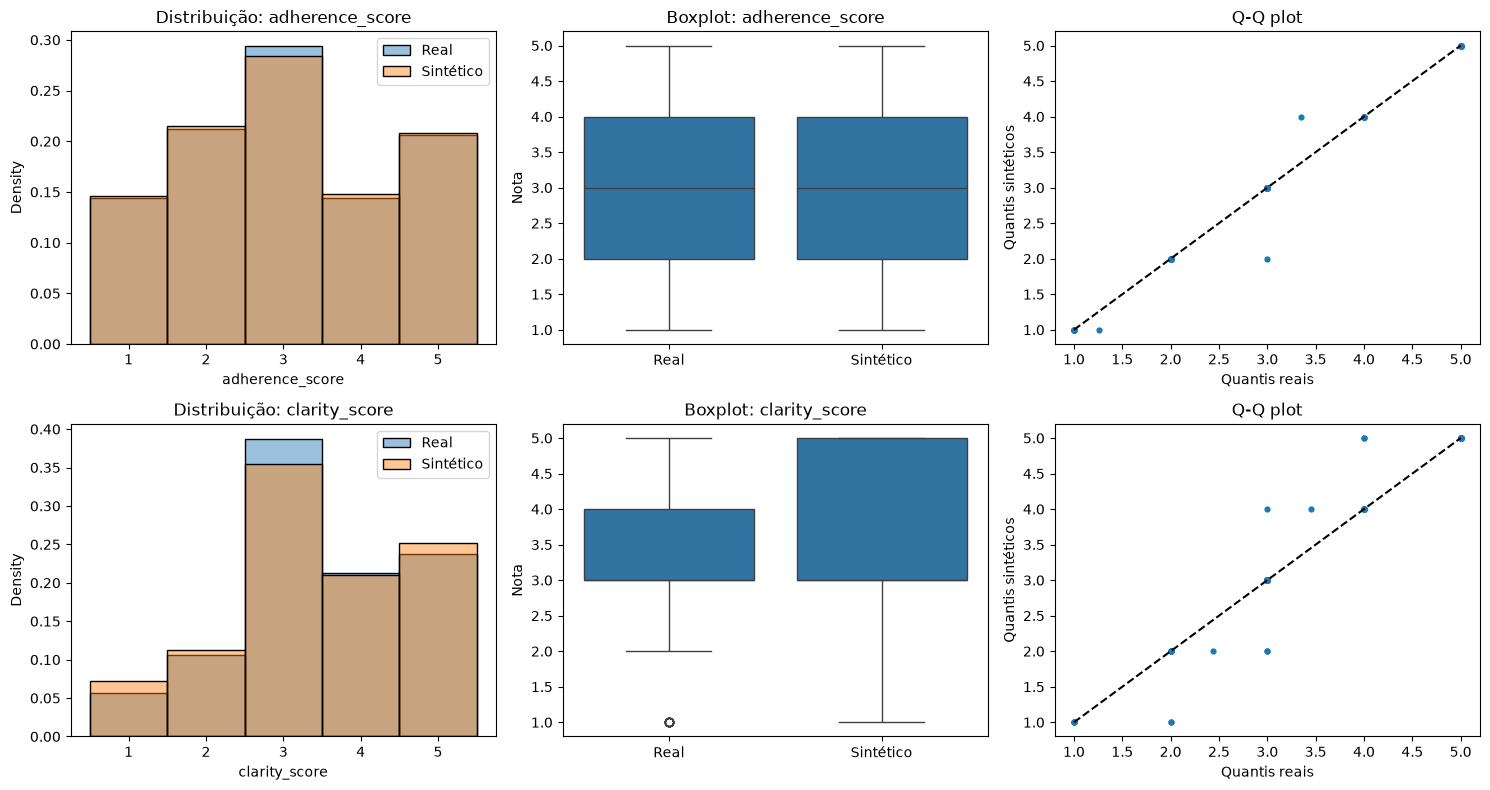

Distâncias Wasserstein:


,distancia
applied,0.0154
adherence_score,0.0139
clarity_score,0.0634


Erro médio absoluto entre correlações: 0.3909
α-Precisão, β-Recall e Autenticidade:


,valor
alpha_precisao,0.9267
beta_recall,1.0000
autenticidade,0.0733
raio_alpha,0.0000
raio_beta,0.0000


Resultados de utility / ML:


,acuracia,precisao,recall,f1
TRTR (real → real),0.7500,0.5882,0.6667,0.6250
TSTR (sintético → real),0.6458,0.4583,0.7333,0.5641
Real → sintético (diagnóstico),0.5227,0.2831,0.3959,0.3301


Fairness: não aplicável — nenhum atributo protegido foi definido na base.


,fonte_json,calculated_at_mongo,recommendation_engine,metrica,valor_json,valor_mongo,diferenca,diferenca_absoluta,coincide
0,metricas_copula.json,2026-10-19 19:26:31.087,bm25,mean_precision_at_k,0.284977,0.306667,-0.021690,0.021690,False
1,metricas_copula.json,2026-10-19 19:26:31.087,bm25,map_at_k,0.446068,0.367500,0.078568,0.078568,False
2,metricas_copula.json,2026-10-19 19:26:31.087,bm25,hit_ratio_at_k,0.819249,0.600000,0.219249,0.219249,False
3,metricas_copula.json,2026-10-19 19:26:31.087,bm25,mrr_at_k,0.463146,0.380000,0.083146,0.083146,False
4,metricas_copula.json,2026-10-19 19:26:31.087,bm25,avg_first_relevant_pos,2.159149,2.631579,-0.472430,0.472430,False
5,metricas_copula.json,2026-10-19 19:26:31.087,bm25,mean_ndcg_at_k,0.897753,0.895679,0.002074,0.002074,False
6,metricas_copula.json,2026-10-19 19:26:31.087,bm25,mean_ep_at_k,0.449296,0.466667,-0.017371,0.017371,False
7,metricas_copula.json,2026-10-19 19:26:31.087,jaccard,mean_precision_at_k,0.301887,0.280000,0.021887,0.021887,False
8,metricas_copula.json,2026-10-19 19:26:31.087,jaccard,map_at_k,0.456112,0.465926,-0.009814,0.009814,False
9,metricas_copula.json,2026-10-19 19:26:31.087,jaccard,hit_ratio_at_k,0.825472,0.733333,0.092138,0.092138,False


In [6]:
# ======================================================================
# 3. Avaliação dos dados sintéticos gerados pela Copula
# ======================================================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import wasserstein_distance
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Comparar somente as variáveis usadas no treinamento da Copula.
colunas_modelo = ['applied', 'adherence_score', 'clarity_score']
target = 'applied'
numericas = ['adherence_score', 'clarity_score']
features = numericas

real = df_treino[colunas_modelo].copy()

# Avaliar apenas as novas linhas geradas, não o dataset final que também
# contém as avaliações reais.
sintetico = df_novas_copula[colunas_modelo].copy()

if sintetico.empty:
    raise ValueError('Não há linhas sintéticas novas para avaliar.')

# Garantir que os dados comparados sejam numéricos.
for df in (real, sintetico):
    for coluna in colunas_modelo:
        df[coluna] = pd.to_numeric(df[coluna], errors='raise')


# Estatísticas descritivas e distribuições marginais.
def distribuicao(df, coluna):
    return df[coluna].value_counts(normalize=True).sort_index()


estatisticas = pd.concat(
    [
        real[numericas].describe().T.add_prefix('real_'),
        sintetico[numericas].describe().T.add_prefix('sintetico_')
    ],
    axis=1
)
display(estatisticas.round(3))

erro_marginal = {}
for coluna in colunas_modelo:
    tabela = pd.concat(
        [distribuicao(real, coluna), distribuicao(sintetico, coluna)],
        axis=1,
        keys=['real', 'sintetico']
    ).fillna(0)

    erro_marginal[coluna] = (
        tabela['real'] - tabela['sintetico']
    ).abs().mean()

display(
    pd.Series(erro_marginal, name='erro_absoluto_medio')
    .to_frame()
    .round(4)
)


# Histogramas, boxplots e Q-Q plots das notas.
fig, axes = plt.subplots(
    len(numericas),
    3,
    figsize=(15, 4 * len(numericas))
)
axes = np.atleast_2d(axes)

for i, coluna in enumerate(numericas):
    sns.histplot(
        real[coluna],
        stat='density',
        discrete=True,
        alpha=.45,
        label='Real',
        ax=axes[i, 0]
    )
    sns.histplot(
        sintetico[coluna],
        stat='density',
        discrete=True,
        alpha=.45,
        label='Sintético',
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f'Distribuição: {coluna}')
    axes[i, 0].legend()

    dados_boxplot = pd.DataFrame({
        'nota': pd.concat(
            [
                real[coluna].reset_index(drop=True),
                sintetico[coluna].reset_index(drop=True)
            ],
            ignore_index=True
        ),
        'origem': (
            ['Real'] * len(real)
            + ['Sintético'] * len(sintetico)
        )
    })
    sns.boxplot(
        data=dados_boxplot,
        x='origem',
        y='nota',
        order=['Real', 'Sintético'],
        ax=axes[i, 1]
    )
    axes[i, 1].set_title(f'Boxplot: {coluna}')
    axes[i, 1].set_xlabel('')
    axes[i, 1].set_ylabel('Nota')

    quantis = np.linspace(.01, .99, 99)
    axes[i, 2].scatter(
        real[coluna].quantile(quantis),
        sintetico[coluna].quantile(quantis),
        s=12
    )

    limites = [
        min(real[coluna].min(), sintetico[coluna].min()),
        max(real[coluna].max(), sintetico[coluna].max())
    ]
    axes[i, 2].plot(limites, limites, '--', color='black')
    axes[i, 2].set_title('Q-Q plot')
    axes[i, 2].set_xlabel('Quantis reais')
    axes[i, 2].set_ylabel('Quantis sintéticos')

plt.tight_layout()
plt.show()


# Distâncias marginais e erro entre correlações das variáveis modeladas.
wasserstein = {
    coluna: wasserstein_distance(real[coluna], sintetico[coluna])
    for coluna in colunas_modelo
}

corr_real = real[colunas_modelo].corr()
corr_sintetico = sintetico[colunas_modelo].corr()
mascara = np.triu(np.ones_like(corr_real, dtype=bool), k=1)

print('Distâncias Wasserstein:')
display(
    pd.Series(wasserstein, name='distancia')
    .to_frame()
    .round(4)
)

erro_correlacao = np.abs(
    (corr_real - corr_sintetico).to_numpy()
)[mascara].mean()

print(f'Erro médio absoluto entre correlações: {erro_correlacao:.4f}')


# Métricas de proximidade usando somente as duas notas.
# Os IDs e o motor de recomendação não participam do embedding.
scaler = StandardScaler().fit(real[features])
Xr = scaler.transform(real[features])
Xs = scaler.transform(sintetico[features])


def raios_knn(X, k=3):
    k = min(k + 1, len(X))
    return NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)[0][:, -1]


def metricas_proximidade(Xr, Xs, alpha=.8, k=3):
    raios_reais = raios_knn(Xr, k)
    raios_sinteticos = raios_knn(Xs, k)

    dist_sintetico_real, indices_reais = (
        NearestNeighbors(n_neighbors=1)
        .fit(Xr)
        .kneighbors(Xs)
    )
    dist_real_sintetico = (
        NearestNeighbors(n_neighbors=1)
        .fit(Xs)
        .kneighbors(Xr)[0]
    )
    dist_vizinhos_reais = (
        NearestNeighbors(n_neighbors=min(2, len(Xr)))
        .fit(Xr)
        .kneighbors(Xr)[0][:, 1]
    )

    return {
        'alpha_precisao': np.mean(
            dist_sintetico_real[:, 0] <= np.quantile(raios_reais, alpha)
        ),
        'beta_recall': np.mean(
            dist_real_sintetico[:, 0] <= np.quantile(raios_sinteticos, alpha)
        ),
        'autenticidade': np.mean(
            dist_sintetico_real[:, 0]
            > dist_vizinhos_reais[indices_reais[:, 0]]
        ),
        'raio_alpha': np.quantile(raios_reais, alpha),
        'raio_beta': np.quantile(raios_sinteticos, alpha)
    }


print('α-Precisão, β-Recall e Autenticidade:')
display(
    pd.Series(metricas_proximidade(Xr, Xs))
    .to_frame('valor')
    .round(4)
)


# Utility: prever applied a partir das duas notas.
def modelo():
    return Pipeline([
        ('scale', StandardScaler()),
        (
            'rf',
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight='balanced'
            )
        )
    ])


def medir(treino, teste):
    classificador = modelo()
    classificador.fit(treino[features], treino[target])
    previsoes = classificador.predict(teste[features])

    return {
        'acuracia': accuracy_score(teste[target], previsoes),
        'precisao': precision_score(
            teste[target], previsoes, zero_division=0
        ),
        'recall': recall_score(
            teste[target], previsoes, zero_division=0
        ),
        'f1': f1_score(
            teste[target], previsoes, zero_division=0
        )
    }


treino_real, teste_real = train_test_split(
    real,
    test_size=.30,
    stratify=real[target],
    random_state=42
)

resultados = pd.DataFrame({
    'TRTR (real → real)': medir(treino_real, teste_real),
    'TSTR (sintético → real)': medir(sintetico, teste_real),
    'Real → sintético (diagnóstico)': medir(treino_real, sintetico)
}).T

print('Resultados de utility / ML:')
display(resultados.round(4))


# Não há atributo protegido definido para avaliar fairness.
print('Fairness: não aplicável — nenhum atributo protegido foi definido na base.')

# Comparação das métricas da Copula com o último relatório persistido no MongoDB.
import json
from pathlib import Path

CAMPOS_METRICAS_RELATORIO = [
    'mean_precision_at_k',
    'map_at_k',
    'hit_ratio_at_k',
    'mrr_at_k',
    'avg_first_relevant_pos',
    'mean_ndcg_at_k',
    'mean_ep_at_k',
]

def comparar_metricas_com_ultimo_relatorio(caminho_json, database):
    caminho_json = Path(caminho_json)
    dados_json = json.loads(caminho_json.read_text(encoding='utf-8'))
    ultimo_relatorio = database['recommendation_metrics_reports'].find_one(
        {}, sort=[('calculated_at', -1)]
    )

    if ultimo_relatorio is None:
        raise ValueError(
            'Nenhum documento encontrado em recommendation_metrics_reports.'
        )

    resultados_mongo = {
        resultado['recommendation_engine']: resultado['metrics']
        for resultado in ultimo_relatorio.get('results', [])
    }
    comparacoes = []
    for resultado_json in dados_json.get('results', []):
        engine = resultado_json['recommendation_engine']
        metricas_mongo = resultados_mongo.get(engine)
        if metricas_mongo is None:
            raise ValueError(
                f'Engine {engine!r} não encontrada no último relatório MongoDB.'
            )

        for campo in CAMPOS_METRICAS_RELATORIO:
            valor_json = float(resultado_json['metrics'][campo])
            valor_mongo = float(metricas_mongo[campo])
            diferenca = valor_json - valor_mongo
            comparacoes.append({
                'fonte_json': caminho_json.name,
                'calculated_at_mongo': ultimo_relatorio['calculated_at'],
                'recommendation_engine': engine,
                'metrica': campo,
                'valor_json': valor_json,
                'valor_mongo': valor_mongo,
                'diferenca': diferenca,
                'diferenca_absoluta': abs(diferenca),
                'coincide': bool(np.isclose(valor_json, valor_mongo)),
            })

    return pd.DataFrame(comparacoes)

comparacao_copula = comparar_metricas_com_ultimo_relatorio(
    'metricas_copula.json',
    db_ors,
)
display(comparacao_copula)

## Rede Bayesiana

Vamos utilizar a biblioteca `pgmpy` para gerar dados sintéticos com base em uma **Rede Bayesiana**, considerando a estrutura manualmente definida de dependência entre as variáveis, assumindo que `Candidatura` é influenciada tanto pelo `Grau de aderência` quanto pelo `Grau de clareza da explicação`.

Dessa forma, vamos calcular probabilidades como qual a probabilidade de ocorrer uma candidatura, dado que o grau de aderência e o grau de clareza da explicação são ambos 1:

$$
P(Candidatura=True \mid Aderencia=1, Explicabilidade=1)
$$

Sendo uma rede neural, temos alguns parâmetros que podem ser ajustados, como o número de amostras a serem geradas e a distribuição de probabilidade condicional (CPD) para cada variável.

Sobre a CPD, foi adotada a BDeu score, que é uma medida de quão bem a estrutura da rede se ajusta aos dados observados, considerando a complexidade do modelo. Ela é adequada para **variáveis discretas, poucos dados reais disponíveis e uma Rede Bayesiana que precisa representar dependências entre avaliações**.

### O que o BDeu está fazendo

BDeu significa **Bayesian Dirichlet equivalent uniform**.

Ele é um score/abordagem bayesiana que combina:

1. **Os dados observados**
2. **Um prior sobre os parâmetros:** Evita que pequenas quantidades de observações produzam estimativas extremas, como 0% ou 100% de probabilidade, usando uma distribuição de probabilidades plausíveis para esse parâmetro.
3. **A estrutura da Rede Bayesiana**
4. **Um princípio de equivalência entre estruturas**

A ideia geral é:

> "Dado o conjunto de dados, quão plausível é essa estrutura de Rede Bayesiana?"

Isso é diferente de simplesmente procurar a estrutura que maximiza a frequência observada.

---

### Por que isso é interessante?

O conjunto pode ser relativamente pequeno. A quantidade efetiva é exibida na variável `df_50` depois da coleta; o nome foi preservado por compatibilidade com as células seguintes.

e cada observação possui:

```text
adherence_score       → 1 a 5 (5 opções)
clarity_score → 1 a 5 (5 opções)
applied      → 0 ou 1 (2 opções)
```

Isso cria potencialmente:

$$
5 \times 5 \times 2 = 50
$$

combinações possíveis.

Ou seja, existem **até 50 configurações diferentes** de:

```text
Aderência + Explicabilidade → Avaliação
```

mas possui apenas cerca de 50 observações.

Algumas combinações podem aparecer várias vezes e outras podem **não aparecer nenhuma vez**.

É aí que uma abordagem bayesiana começa a ser útil.

---

### O problema de usar apenas as frequências

Imagine que seus dados tenham:

| Aderência | Explicabilidade | Avaliação |
| --------: | --------------: | --------: |
|         5 |               5 |         1 |
|         5 |               5 |         1 |
|         5 |               5 |         1 |
|         5 |               5 |         1 |
|         5 |               5 |         1 |

Você observou:

$$
P(Avaliacao=1|5,5)=1
$$

Mas isso aconteceu com apenas **5 observações**.

Uma estimativa puramente baseada em frequência poderia interpretar isso como:

> "Quando aderência = 5 e explicabilidade = 5, a probabilidade é 100%."

Isso pode ser excessivamente confiante.

O BDeu introduz um **prior**, evitando que pequenas quantidades de observações produzam estimativas tão extremas.

---

# O papel do `equivalent_sample_size` (ESS)

```python
BayesianEstimator(
    model,
    data=df,
    prior_type='BDeu',
    equivalent_sample_size=10
)
```

O:

```python
equivalent_sample_size=10
```

controla a **força do prior**.

Imagine, simplificadamente:

```text
Dados observados
       +
"observações virtuais" do prior
       ↓
estimativa final
```

Não significa que o modelo literalmente adicionou 10 linhas ao DataFrame.

É uma maneira de parametrizar a força da informação prévia.

### ESS pequeno

Por exemplo:

```text
ESS = 1
```

O modelo confia muito mais nos dados observados.

### ESS grande

```text
ESS = 100
```

O prior (distribuição a priori, 'distribuições plausíveis') tem muito mais influência

Portanto:

```text
ESS
 │
 ├── pequeno → dados dominam
 │
 └── grande  → prior domina mais
```

**10 é uma escolha razoável como ponto de partida** pra evitar estimativas excessivamente extremas, mas é importante verificar a sensibilidade dos resultados a valores como 1, 5, 10 e 20.

---

### E o "equivalent" do BDeu?

Considere duas estruturas:

```text
A → B
```

e

```text
A ← B
```

Em determinadas condições, elas podem representar as mesmas **independências condicionais**.

Essas estruturas pertencem ao que chamamos de **classe de equivalência de Markov**.

O BDeu foi construído para atribuir o mesmo score a estruturas Markov-equivalentes.

Isso é importante porque evita que o algoritmo diga:

> "Essa direção é melhor simplesmente por causa da parametrização."

quando, do ponto de vista das independências probabilísticas representadas, as estruturas são equivalentes.

### Resumo sobre BDeu

BDeu é uma escolha metodologicamente coerente com o seu cenário por quatro motivos.

### 1. Variáveis são discretas

```text
Aderência          → 1–5 (inteiro)
Explicabilidade    → 1–5 (inteiro)
Avaliação binária  → 0–1 (binário)
```
---

### 2. Poucos dados

Com apenas dezenas de usuários, algumas combinações das variáveis podem ter poucas observações.

O componente bayesiano permite incorporar um prior e **reduzir estimativas extremamente dependentes de pequenas frequências observadas usando prior**.

---

### 3. Rede probabilística interpretável

Com o objetivo de comparar isso:

$$
P(Avaliacao=1\mid Aderencia=5,Explicabilidade=5)
$$

com isso:

$$
P(Avaliacao=1\mid Aderencia=1,Explicabilidade=1)
$$

O modelo bayesiano fornece uma estrutura natural para essas probabilidades condicionais.

### Duas redes que planejamos:

#### Opção 1: Aderência pode justificar clareza, assim como elas unidas justificam uma candidatura
$$
\begin{aligned}
P(Ad,C,App) =P(Ad) \cdot P(C\mid Ad) \cdot P(App\mid Ad,C) \end{aligned}
$$

Onde :

* $Ad$: Aderência
* $App$: Candidatura
* $C$: Clareza





/home/lsarai/tcc-knowledge-management/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== Estrutura da rede ===


/home/lsarai/tcc-knowledge-management/.venv/lib/python3.12/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (
/tmp/ipykernel_2905/2964383109.py:23: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimador = BayesianEstimator(model=modelo, data=dados)


,causa,efeito
0,adherence_score,clarity_score
1,adherence_score,applied
2,clarity_score,applied


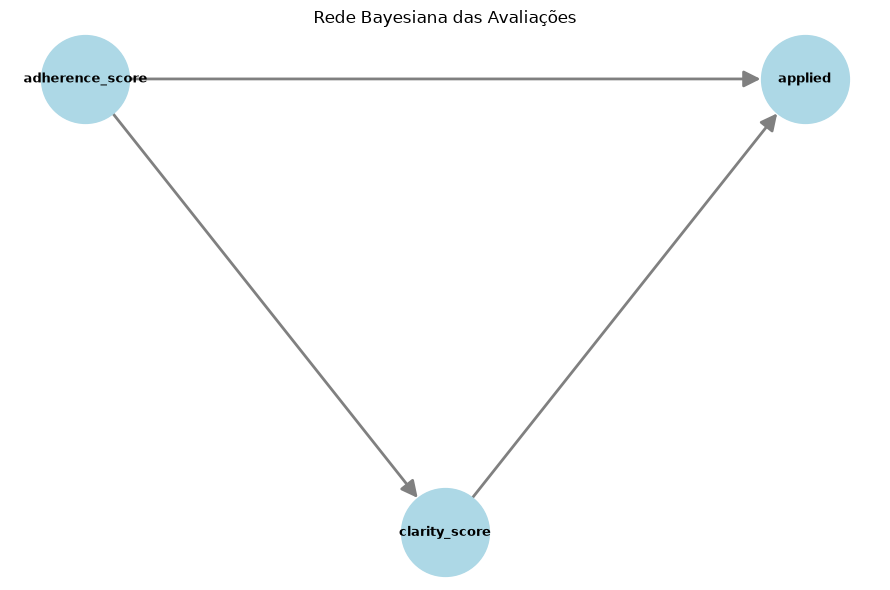

=== CPDs estimadas com dados reais ===


,adherence_score,probability,modelo,variavel,1,2,3,4,5,clarity_score,0
0,1,0.147059,real,adherence_score,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,0.211765,real,adherence_score,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,0.288235,real,adherence_score,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,0.147059,real,adherence_score,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,0.205882,real,adherence_score,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1,NaN,real,clarity_score,0.296000,0.136000,0.096000,0.176000,0.296000,NaN,NaN
6,2,NaN,real,clarity_score,0.038889,0.316667,0.233333,0.316667,0.094444,NaN,NaN
7,3,NaN,real,clarity_score,0.028571,0.008163,0.804082,0.110204,0.048980,NaN,NaN
8,4,NaN,real,clarity_score,0.016000,0.136000,0.456000,0.176000,0.216000,NaN,NaN
9,5,NaN,real,clarity_score,0.011429,0.011429,0.068571,0.297143,0.611429,NaN,NaN


=== Probabilidades posteriores estimadas com dados reais ===


,aderencia,explicabilidade,"P(candidatura | notas, real)"
0,1,1,0.0270
1,1,2,0.3529
2,1,3,0.0833
3,1,4,0.0455
4,1,5,0.0270
5,2,1,0.1429
6,2,2,0.1053
7,2,3,0.0238
8,2,4,0.1930
9,2,5,0.0588


=== Sensibilidade local com dados reais ===


,variavel,amplitude_P_real
0,adherence_score,0.5085
1,clarity_score,0.1820


In [7]:
# ======================================================================
# 8. Probabilidades com uma rede bayesiana discreta
# ======================================================================
# A rede é ajustada somente com os dados reais; a Gaussian Copula permanece
# como o sintetizador independente usado na avaliação anterior.
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination
import matplotlib.pyplot as plt
import networkx as nx

variaveis_bn = ['adherence_score', 'clarity_score', 'applied']
# Estrutura interpretável: as notas ajudam a explicar a avaliação binária.
arcos_bn = [
    ('adherence_score', 'clarity_score'),
    ('adherence_score', 'applied'),
    ('clarity_score', 'applied')
]

def ajustar_bn(df):
    dados = df[variaveis_bn].copy().astype(int)
    modelo = DiscreteBayesianNetwork(arcos_bn)
    estimador = BayesianEstimator(model=modelo, data=dados)
    modelo.add_cpds(*estimador.get_parameters(
        prior_type='BDeu',
        equivalent_sample_size=10
    ))
    return modelo

bn_real = ajustar_bn(real)

print('=== Estrutura da rede ===')
display(pd.DataFrame(arcos_bn, columns=['causa', 'efeito']))


plt.figure(figsize=(9, 6))

pos = {
    'adherence_score': (0, 1),
    'clarity_score': (1, 0),
    'applied': (2, 1)
}

nx.draw_networkx(
    bn_real,
    pos=pos,
    with_labels=True,
    node_size=4000,
    node_color='lightblue',
    font_size=9,
    font_weight='bold',
    arrows=True,
    arrowsize=25,
    edge_color='gray',
    width=2,
    node_shape='o'
)

plt.title('Rede Bayesiana das Avaliações')
plt.axis('off')
plt.tight_layout()
plt.show()

# CPDs representam as probabilidades estimadas somente a partir dos dados reais.
def extrair_cpd(modelo, nome_modelo):
    tabelas = []
    for cpd in modelo.get_cpds():
        if len(cpd.variables) == 1:
            tabela = pd.DataFrame({
                cpd.variable: cpd.state_names[cpd.variable],
                'probability': cpd.get_values().reshape(-1)
            })
        else:
            tabela = cpd.to_dataframe().reset_index()
        tabela['modelo'] = nome_modelo
        tabela['variavel'] = cpd.variable
        tabelas.append(tabela)
    return pd.concat(tabelas, ignore_index=True)

cpds_reais = extrair_cpd(bn_real, 'real')
print('=== CPDs estimadas com dados reais ===')
display(cpds_reais)

# Consulta posterior: probabilidade da candidatura para cada perfil observado de notas.
def probabilidade_positiva(modelo, aderencia, explicabilidade):
    inferencia = VariableElimination(modelo)
    posterior = inferencia.query(
        variables=['applied'],
        evidence={
            'adherence_score': int(aderencia),
            'clarity_score': int(explicabilidade)
        },
        show_progress=False
    )
    estados = list(posterior.state_names['applied'])
    return float(posterior.values[estados.index(1)])

consultas_reais = []
for aderencia in sorted(real['adherence_score'].unique()):
    for explicabilidade in sorted(real['clarity_score'].unique()):
        consultas_reais.append({
            'aderencia': aderencia,
            'explicabilidade': explicabilidade,
            'P(candidatura | notas, real)': probabilidade_positiva(
                bn_real, aderencia, explicabilidade
            )
        })
posteriores_reais = pd.DataFrame(consultas_reais)
print('=== Probabilidades posteriores estimadas com dados reais ===')
display(posteriores_reais.round(4))

# Sensibilidade local: variação média da probabilidade ao mudar uma nota.
sensibilidade_real = pd.DataFrame({
    'variavel': ['adherence_score', 'clarity_score'],
    'amplitude_P_real': [
        posteriores_reais.groupby('aderencia')['P(candidatura | notas, real)'].mean().max()
        - posteriores_reais.groupby('aderencia')['P(candidatura | notas, real)'].mean().min(),
        posteriores_reais.groupby('explicabilidade')['P(candidatura | notas, real)'].mean().max()
        - posteriores_reais.groupby('explicabilidade')['P(candidatura | notas, real)'].mean().min()
    ]
})
print('=== Sensibilidade local com dados reais ===')
display(sensibilidade_real.round(4))

### Conclusão sobre as probabilidades

Pela tabela CPD, nota-se que aderência não justifica clareza, o que explica a baixa correlação encontrada na etapa anterior entre essas variáveis. Por exemplo, a nota 1 de aderência tem a mesma 27% de probabilidade de vir acompanhada da nota 1 ou 5 em clareza, assim como a nota 2 de aderência costuma vir acompanhada da nota 4 de clareza.

Sendo assim, não se justifica a probabilidade condicional entre elas adicionada

#### Opção 2: Aderência não justifica clareza, assim como elas unidas justificam uma candidatura
$$
\begin{aligned}
P(Ad,C,App) =P(Ad) \cdot P(C) \cdot P(App\mid Ad,C) \end{aligned}
$$

=== Estrutura da rede ===


/tmp/ipykernel_2905/2964383109.py:23: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  estimador = BayesianEstimator(model=modelo, data=dados)


,causa,efeito
0,adherence_score,applied
1,clarity_score,applied


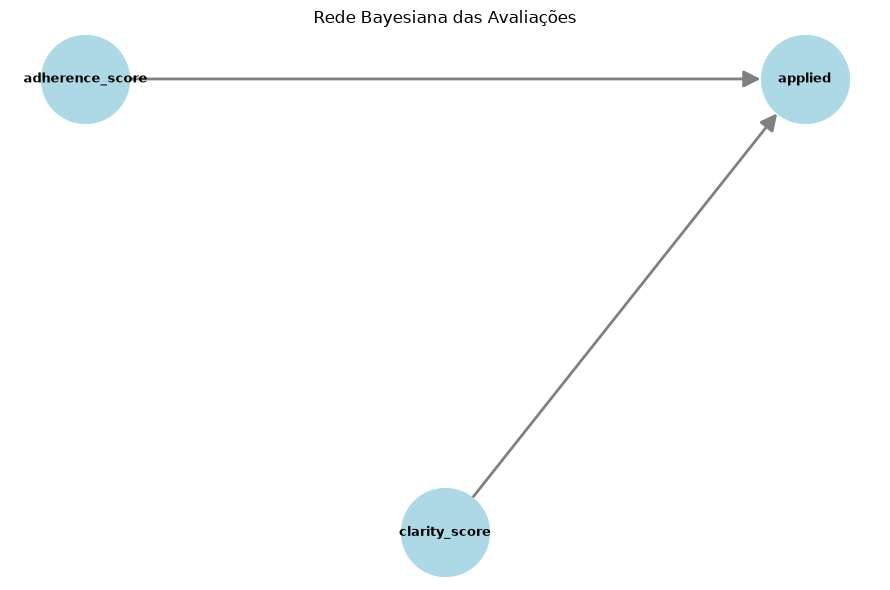

=== CPDs estimadas com dados reais ===


,adherence_score,probability,modelo,variavel,clarity_score,0,1
0,1.0,0.147059,real,adherence_score,NaN,NaN,NaN
1,2.0,0.211765,real,adherence_score,NaN,NaN,NaN
2,3.0,0.288235,real,adherence_score,NaN,NaN,NaN
3,4.0,0.147059,real,adherence_score,NaN,NaN,NaN
4,5.0,0.205882,real,adherence_score,NaN,NaN,NaN
5,1.0,NaN,real,applied,1.0,0.972973,0.027027
6,1.0,NaN,real,applied,2.0,0.647059,0.352941
7,1.0,NaN,real,applied,3.0,0.916667,0.083333
8,1.0,NaN,real,applied,4.0,0.954545,0.045455
9,1.0,NaN,real,applied,5.0,0.972973,0.027027


=== Probabilidades posteriores estimadas com dados reais ===


,aderencia,explicabilidade,"P(candidatura | notas, real)"
0,1,1,0.0270
1,1,2,0.3529
2,1,3,0.0833
3,1,4,0.0455
4,1,5,0.0270
5,2,1,0.1429
6,2,2,0.1053
7,2,3,0.0238
8,2,4,0.1930
9,2,5,0.0588


=== Sensibilidade local com dados reais ===


,variavel,amplitude_P_real
0,adherence_score,0.5085
1,clarity_score,0.1820


In [8]:
# Estrutura interpretável: as notas ajudam a explicar a avaliação binária.
arcos_bn = [
    ('adherence_score', 'applied'),
    ('clarity_score', 'applied')
]

bn_real = ajustar_bn(real)

print('=== Estrutura da rede ===')
display(pd.DataFrame(arcos_bn, columns=['causa', 'efeito']))


plt.figure(figsize=(9, 6))

pos = {
    'adherence_score': (0, 1),
    'clarity_score': (1, 0),
    'applied': (2, 1)
}

nx.draw_networkx(
    bn_real,
    pos=pos,
    with_labels=True,
    node_size=4000,
    node_color='lightblue',
    font_size=9,
    font_weight='bold',
    arrows=True,
    arrowsize=25,
    edge_color='gray',
    width=2,
    node_shape='o'
)

plt.title('Rede Bayesiana das Avaliações')
plt.axis('off')
plt.tight_layout()
plt.show()

cpds_reais = extrair_cpd(bn_real, 'real')
print('=== CPDs estimadas com dados reais ===')
display(cpds_reais)

consultas_reais = []
for aderencia in sorted(real['adherence_score'].unique()):
    for explicabilidade in sorted(real['clarity_score'].unique()):
        consultas_reais.append({
            'aderencia': aderencia,
            'explicabilidade': explicabilidade,
            'P(candidatura | notas, real)': probabilidade_positiva(
                bn_real, aderencia, explicabilidade
            )
        })
posteriores_reais = pd.DataFrame(consultas_reais)
print('=== Probabilidades posteriores estimadas com dados reais ===')
display(posteriores_reais.round(4))

# Sensibilidade local: variação média da probabilidade ao mudar uma nota.
sensibilidade_real = pd.DataFrame({
    'variavel': ['adherence_score', 'clarity_score'],
    'amplitude_P_real': [
        posteriores_reais.groupby('aderencia')['P(candidatura | notas, real)'].mean().max()
        - posteriores_reais.groupby('aderencia')['P(candidatura | notas, real)'].mean().min(),
        posteriores_reais.groupby('explicabilidade')['P(candidatura | notas, real)'].mean().max()
        - posteriores_reais.groupby('explicabilidade')['P(candidatura | notas, real)'].mean().min()
    ]
})
print('=== Sensibilidade local com dados reais ===')
display(sensibilidade_real.round(4))

### Conclusão sobre essa opção

Ficou mais coerente, pois Clareza e Aderência se tornaram independentes entre si, enquanto Candidatura se manteve dependente delas, como se nota que com notas mais altas nessas pontuações, as probabilidades de candidatura subiam para quase 90%, enquanto que, no cenário oposto onde as notas eram baixas, as chances de não candidatura também beiravam 90%

### Entendendo a tabela CPD

Caso fiquem confusos com ela, vamos analisar alguns exemplos para esclarecer:

**Linha 0:**

| Coluna | Significado nesta linha |
|---|---|
| `adherence_score = 1.0` | O estado considerado é nota de aderência igual a 1. |
| `probability = 0.133333` | A rede estima cerca de **13,33%** para esse estado, isto é, $P(\text{Likert\_Aderencia}=1)$. A estimativa usa o prior BDeu, então pode diferir da frequência bruta dos dados. |
| `modelo = real` | A rede foi ajustada com os dados reais. |
| `variavel = adherence_score` | Identifica a variável cuja distribuição está sendo mostrada. |
| `clarity_score = NaN` | Não se aplica a esta linha: ela mostra a distribuição marginal da aderência, não uma combinação de notas. |
| `0 = NaN` e `1 = NaN` | Essas colunas são usadas para as probabilidades da `applied` condicionadas às notas. Não se aplicam à distribuição marginal da aderência. |

Em resumo, a linha diz: **nos dados reais, a rede estima 13,33% de probabilidade para a nota de aderência 1**.

**Linha 15:**

| Coluna | Significado nesta linha |
|---|---|
| `adherence_score = 3.0` | Nota de aderência considerada nesta condição. |
| `probability = NaN` | Não se aplica a esta CPD condicional; as probabilidades estão nas colunas `0` e `1`. |
| `modelo = real` | As probabilidades foram estimadas com os dados reais. |
| `variavel = applied` | Variável cujo resultado está sendo estimado. |
| `clarity_score = 1.0` | Nota de explicabilidade considerada nesta condição. |
| `0 = 0.500000` | Probabilidade estimada de a avaliação binária ser `0`: 50%. |
| `1 = 0.500000` | Probabilidade estimada de a avaliação binária ser `1`: 50%. |

Em resumo, a linha diz: **para aderência 3 e explicabilidade 1, a rede estima chances iguais para a avaliação ser 0 ou 1**.

**Linha 30:**

| Coluna | Significado nesta linha |
|---|---|
| `adherence_score = NaN` | Não se aplica: esta linha descreve a distribuição marginal da explicabilidade. |
| `probability = 0.116667` | Probabilidade estimada de a nota de explicabilidade ser `1`: cerca de **11,67%**. |
| `modelo = real` | A probabilidade foi estimada com os dados reais. |
| `variavel = clarity_score` | Identifica a variável descrita nesta linha. |
| `clarity_score = 1.0` | Estado considerado: nota de explicabilidade igual a 1. |
| `0 = NaN` e `1 = NaN` | Não se aplicam aqui; essas colunas mostram as probabilidades da `applied` nas linhas condicionais. |

Em resumo, a linha diz: **com base nos dados reais, a rede estima 11,67% de probabilidade para a nota de explicabilidade 1**.

Ou seja, a tabela apresenta, de forma agregada, uma probabilidade de ocorrência de cada valor de forma individual (marginal) e também as probabilidades condicionais de uma variável em relação a outras.

=== Amostra de registros gerados pela rede bayesiana ===
Quantidade de registros novos: 4090


,applied,adherence_score,clarity_score
0,1,3,4
1,0,5,3
2,1,4,3
3,0,3,5
4,0,2,3


=== Estatísticas descritivas ===


,real_count,real_mean,real_std,real_min,real_25%,real_50%,real_75%,real_max,bn_count,bn_mean,bn_std,bn_min,bn_25%,bn_50%,bn_75%,bn_max
adherence_score,160.0,3.056,1.328,1.0,2.0,3.0,4.0,5.0,4090.0,3.047,1.341,1.0,2.0,3.0,4.0,5.0
clarity_score,160.0,3.469,1.132,1.0,3.0,3.0,4.0,5.0,4090.0,3.409,1.147,1.0,3.0,3.0,4.0,5.0


=== Erro absoluto médio das distribuições marginais ===


,erro_absoluto_medio
adherence_score,0.0052
clarity_score,0.0084
applied,0.0059


=== Distâncias Wasserstein ===


,distancia
applied,0.0059
adherence_score,0.0220
clarity_score,0.0602


Erro médio absoluto entre correlações: 0.3095
=== Métricas de vizinhança ===


,valor
alpha_precisao,0.9198
beta_recall,1.0000
autenticidade,0.0802
raio_alpha,0.0000
raio_beta,0.0000


Atenção: com duas notas Likert existem no máximo 25 perfis; repetições podem zerar os raios kNN e saturar as métricas.


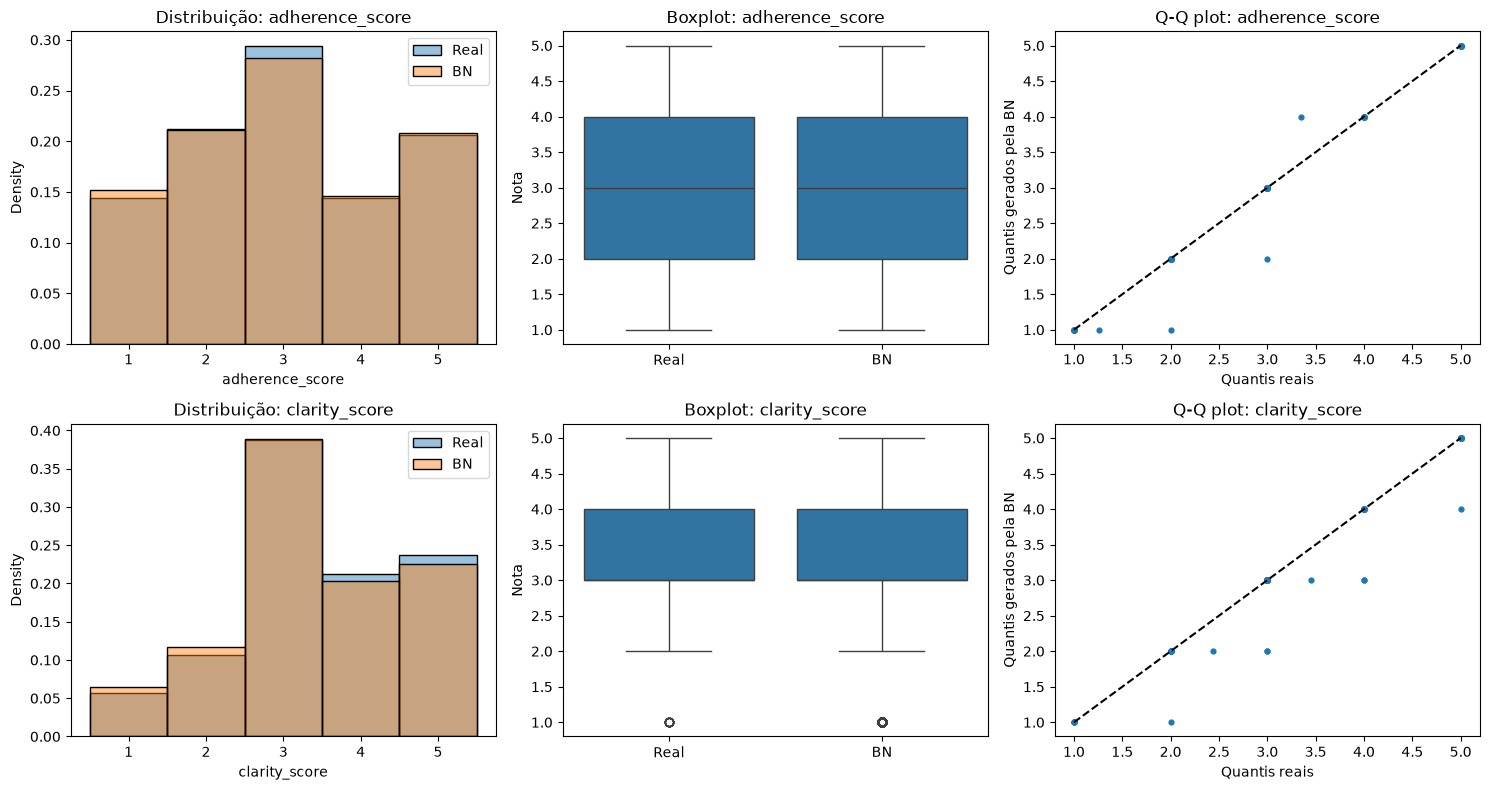

=== Utilidade preditiva ===


,acuracia,precisao,recall,f1
TRTR (real → real),0.7500,0.5882,0.6667,0.6250
BN-train (BN → real),0.7500,0.5789,0.7333,0.6471
Real-train (real → BN),0.7504,0.5689,0.7671,0.6533


Fairness: não avaliada — a base não contém atributo protegido.
Registros novos gerados pela BN: 4090
Quantidade de resume_id sem avaliações: 411
Quantidade de registros do df_sintetico_bn: 4250


,fonte_json,calculated_at_mongo,recommendation_engine,metrica,valor_json,valor_mongo,diferenca,diferenca_absoluta,coincide
0,metricas_bn.json,2026-10-19 19:26:31.087,bm25,mean_precision_at_k,0.377934,0.306667,0.071268,0.071268,False
1,metricas_bn.json,2026-10-19 19:26:31.087,bm25,map_at_k,0.557205,0.367500,0.189705,0.189705,False
2,metricas_bn.json,2026-10-19 19:26:31.087,bm25,hit_ratio_at_k,0.894366,0.600000,0.294366,0.294366,False
3,metricas_bn.json,2026-10-19 19:26:31.087,bm25,mrr_at_k,0.595970,0.380000,0.215970,0.215970,False
4,metricas_bn.json,2026-10-19 19:26:31.087,bm25,avg_first_relevant_pos,1.677936,2.631579,-0.953643,0.953643,False
5,metricas_bn.json,2026-10-19 19:26:31.087,bm25,mean_ndcg_at_k,0.891497,0.895679,-0.004182,0.004182,False
6,metricas_bn.json,2026-10-19 19:26:31.087,bm25,mean_ep_at_k,0.438028,0.466667,-0.028638,0.028638,False
7,metricas_bn.json,2026-10-19 19:26:31.087,jaccard,mean_precision_at_k,0.303774,0.280000,0.023774,0.023774,False
8,metricas_bn.json,2026-10-19 19:26:31.087,jaccard,map_at_k,0.456607,0.465926,-0.009319,0.009319,False
9,metricas_bn.json,2026-10-19 19:26:31.087,jaccard,hit_ratio_at_k,0.825472,0.733333,0.092138,0.092138,False


In [ ]:
# ======================================================================
# 9. Geração e avaliação de registros sintéticos pela rede bayesiana
# ======================================================================
from pgmpy.sampling import BayesianModelSampling
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import wasserstein_distance
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# A BN e as métricas usam somente as variáveis de avaliação.
variaveis_bn = ['applied', 'adherence_score', 'clarity_score']
notas_bn = ['adherence_score', 'clarity_score']

# Não inclua IDs ou recommendation_engine na entrada do modelo.
if set(bn_real.nodes()) != set(variaveis_bn):
    raise ValueError(
        'bn_real deve conter somente applied, adherence_score e clarity_score. '
        'Revise a célula de treinamento da rede bayesiana.'
    )

real_bn = df_treino[variaveis_bn].copy().astype(int)

# Gerar uma avaliação sintética para cada par recomendado pendente.
amostrador_bn = BayesianModelSampling(bn_real)

if len(df_avaliacoes_pendentes):
    sintetico_bn = amostrador_bn.forward_sample(
        size=len(df_avaliacoes_pendentes),
        seed=42,
        show_progress=False
    )[variaveis_bn].astype(int)

    # IDs reais são anexados depois da amostragem; não são gerados pela BN.
    df_novas_bn = montar_registros_com_ids(
        sintetico_bn,
        df_avaliacoes_pendentes
    )
else:
    sintetico_bn = pd.DataFrame(columns=variaveis_bn).astype(int)
    df_novas_bn = pd.DataFrame(columns=colunas_base)

if sintetico_bn.empty:
    raise ValueError(
        'Não há registros sintéticos novos para calcular as métricas.'
    )

# O resultado final preserva as avaliações reais e acrescenta as novas.
df_sintetico_bn = pd.concat(
    [df_treino[colunas_base], df_novas_bn[colunas_base]],
    ignore_index=True
).sort_values(
    ['resume_id', 'recommendation_engine'],
    kind='mergesort'
).reset_index(drop=True)

# ---------------------DESCOMENTE AQUI, SE NECESSÁRIO---------------------------
# df_sintetico_bn.to_csv("bn_sintetico.csv", sep=",", index=False)
# ------------------------------------------------------------------------------

print('=== Amostra de registros gerados pela rede bayesiana ===')
print(f'Quantidade de registros novos: {len(sintetico_bn)}')
display(sintetico_bn.head())

# Estatísticas descritivas das notas reais e geradas pela BN.
estatisticas_bn = pd.concat(
    [
        real_bn[notas_bn].describe().T.add_prefix('real_'),
        sintetico_bn[notas_bn].describe().T.add_prefix('bn_')
    ],
    axis=1
)
print('=== Estatísticas descritivas ===')
display(estatisticas_bn.round(3))

# Erro médio das distribuições marginais nos estados possíveis.
estados_bn = {
    'adherence_score': [1, 2, 3, 4, 5],
    'clarity_score': [1, 2, 3, 4, 5],
    'applied': [0, 1]
}
erro_marginal_bn = {}

for coluna, estados in estados_bn.items():
    tabela = pd.concat(
        [
            real_bn[coluna].value_counts(normalize=True).reindex(
                estados, fill_value=0
            ),
            sintetico_bn[coluna].value_counts(normalize=True).reindex(
                estados, fill_value=0
            )
        ],
        axis=1,
        keys=['real', 'bn']
    )
    erro_marginal_bn[coluna] = (
        tabela['real'] - tabela['bn']
    ).abs().mean()

print('=== Erro absoluto médio das distribuições marginais ===')
display(
    pd.Series(erro_marginal_bn, name='erro_absoluto_medio')
    .to_frame()
    .round(4)
)

# Distâncias Wasserstein e diferença entre correlações.
wasserstein_bn = {
    coluna: wasserstein_distance(real_bn[coluna], sintetico_bn[coluna])
    for coluna in variaveis_bn
}

corr_real_bn = real_bn[variaveis_bn].corr()
corr_sintetico_bn = sintetico_bn[variaveis_bn].corr()
mascara_bn = np.triu(
    np.ones_like(corr_real_bn, dtype=bool),
    k=1
)
erro_correlacao_bn = np.abs(
    (corr_real_bn - corr_sintetico_bn).to_numpy()
)[mascara_bn].mean()

print('=== Distâncias Wasserstein ===')
display(
    pd.Series(wasserstein_bn, name='distancia')
    .to_frame()
    .round(4)
)
print(f'Erro médio absoluto entre correlações: {erro_correlacao_bn:.4f}')

# Métricas de vizinhança: somente as duas notas, sem IDs ou engine.
def raios_knn_bn(X, k=3):
    n_vizinhos = min(k + 1, len(X))
    return (
        NearestNeighbors(n_neighbors=n_vizinhos)
        .fit(X)
        .kneighbors(X)[0][:, -1]
    )


def metricas_vizinhanca_bn(X_real, X_sintetico, alpha=.8, k=3):
    raios_reais = raios_knn_bn(X_real, k)
    raios_sinteticos = raios_knn_bn(X_sintetico, k)

    dist_sintetico_real, indices_reais = (
        NearestNeighbors(n_neighbors=1)
        .fit(X_real)
        .kneighbors(X_sintetico)
    )
    dist_real_sintetico = (
        NearestNeighbors(n_neighbors=1)
        .fit(X_sintetico)
        .kneighbors(X_real)[0]
    )
    dist_vizinhos_reais = (
        NearestNeighbors(n_neighbors=min(2, len(X_real)))
        .fit(X_real)
        .kneighbors(X_real)[0][:, 1]
    )

    return {
        'alpha_precisao': np.mean(
            dist_sintetico_real[:, 0]
            <= np.quantile(raios_reais, alpha)
        ),
        'beta_recall': np.mean(
            dist_real_sintetico[:, 0]
            <= np.quantile(raios_sinteticos, alpha)
        ),
        'autenticidade': np.mean(
            dist_sintetico_real[:, 0]
            > dist_vizinhos_reais[indices_reais[:, 0]]
        ),
        'raio_alpha': np.quantile(raios_reais, alpha),
        'raio_beta': np.quantile(raios_sinteticos, alpha)
    }


escala_bn = StandardScaler()
Xr_bn = escala_bn.fit_transform(real_bn[notas_bn])
Xs_bn = escala_bn.transform(sintetico_bn[notas_bn])

metricas_vizinhanca = metricas_vizinhanca_bn(Xr_bn, Xs_bn)
print('=== Métricas de vizinhança ===')
display(
    pd.Series(metricas_vizinhanca, name='valor')
    .to_frame()
    .round(4)
)
print(
    'Atenção: com duas notas Likert existem no máximo 25 perfis; '
    'repetições podem zerar os raios kNN e saturar as métricas.'
)

# Comparação gráfica das notas reais e geradas pela BN.
fig, axes = plt.subplots(
    len(notas_bn),
    3,
    figsize=(15, 4 * len(notas_bn))
)
axes = np.atleast_2d(axes)

for i, coluna in enumerate(notas_bn):
    sns.histplot(
        real_bn[coluna],
        stat='density',
        discrete=True,
        alpha=.45,
        label='Real',
        ax=axes[i, 0]
    )
    sns.histplot(
        sintetico_bn[coluna],
        stat='density',
        discrete=True,
        alpha=.45,
        label='BN',
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f'Distribuição: {coluna}')
    axes[i, 0].legend()

    dados_boxplot = pd.DataFrame({
        'nota': pd.concat(
            [
                real_bn[coluna].reset_index(drop=True),
                sintetico_bn[coluna].reset_index(drop=True)
            ],
            ignore_index=True
        ),
        'origem': (
            ['Real'] * len(real_bn)
            + ['BN'] * len(sintetico_bn)
        )
    })
    sns.boxplot(
        data=dados_boxplot,
        x='origem',
        y='nota',
        order=['Real', 'BN'],
        ax=axes[i, 1]
    )
    axes[i, 1].set_title(f'Boxplot: {coluna}')
    axes[i, 1].set_xlabel('')
    axes[i, 1].set_ylabel('Nota')

    quantis = np.linspace(.01, .99, 99)
    quantis_reais = real_bn[coluna].quantile(quantis)
    quantis_bn = sintetico_bn[coluna].quantile(quantis)

    axes[i, 2].scatter(quantis_reais, quantis_bn, s=12)
    limites = [
        min(real_bn[coluna].min(), sintetico_bn[coluna].min()),
        max(real_bn[coluna].max(), sintetico_bn[coluna].max())
    ]
    axes[i, 2].plot(limites, limites, '--', color='black')
    axes[i, 2].set_title(f'Q-Q plot: {coluna}')
    axes[i, 2].set_xlabel('Quantis reais')
    axes[i, 2].set_ylabel('Quantis gerados pela BN')

plt.tight_layout()
plt.show()

# Utilidade preditiva: usar as notas para prever applied.
def modelo_bn():
    return Pipeline([
        ('escala', StandardScaler()),
        (
            'rf',
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                class_weight='balanced'
            )
        )
    ])


def medir_bn(treino, teste):
    classificador = modelo_bn()
    classificador.fit(treino[notas_bn], treino['applied'])
    predicoes = classificador.predict(teste[notas_bn])

    return {
        'acuracia': accuracy_score(teste['applied'], predicoes),
        'precisao': precision_score(
            teste['applied'], predicoes, zero_division=0
        ),
        'recall': recall_score(
            teste['applied'], predicoes, zero_division=0
        ),
        'f1': f1_score(
            teste['applied'], predicoes, zero_division=0
        )
    }


real_train_bn, real_test_bn = train_test_split(
    real_bn,
    test_size=.30,
    stratify=real_bn['applied'],
    random_state=42
)

resultados_utility_bn = pd.DataFrame({
    'TRTR (real → real)': medir_bn(real_train_bn, real_test_bn),
    'BN-train (BN → real)': medir_bn(sintetico_bn, real_test_bn),
    'Real-train (real → BN)': medir_bn(real_train_bn, sintetico_bn)
}).T

print('=== Utilidade preditiva ===')
display(resultados_utility_bn.round(4))

print('Fairness: não avaliada — a base não contém atributo protegido.')
print(f'Registros novos gerados pela BN: {len(df_novas_bn)}')
print(
    'Quantidade de resume_id sem avaliações: '
    f'{df_resume_engine_sem_avaliacao["resume_id"].nunique()}'
)
print(f'Quantidade de registros do df_sintetico_bn: {len(df_sintetico_bn)}')

comparacao_bn = comparar_metricas_com_ultimo_relatorio(
    'metricas_bn.json',
    db_ors,
)
display(comparacao_bn)

## CTGAN

Treino e geração usando a implementação oficial do SDV, com as mesmas variáveis e os mesmos pares pendentes.

In [ ]:
from sdv.single_table import CTGANSynthesizer

synthesizer_ctgan = CTGANSynthesizer(metadata)
synthesizer_ctgan.fit(df_modelo)

if len(df_avaliacoes_pendentes):
    sintetico_ctgan = synthesizer_ctgan.sample(
        num_rows=len(df_avaliacoes_pendentes)
    )[colunas_modelo].reset_index(drop=True)
    df_novas_ctgan = montar_registros_com_ids(
        sintetico_ctgan, df_avaliacoes_pendentes
    )
else:
    sintetico_ctgan = pd.DataFrame(columns=colunas_modelo)
    df_novas_ctgan = pd.DataFrame(columns=colunas_base)

if sintetico_ctgan.empty:
    raise ValueError('Não há registros sintéticos novos gerados pelo CTGAN.')

df_sintetico_ctgan = pd.concat(
    [df_treino[colunas_base], df_novas_ctgan[colunas_base]],
    ignore_index=True
).sort_values(
    ['resume_id', 'recommendation_engine'], kind='mergesort'
).reset_index(drop=True)

# DESCOMENTE AQUI, SE NECESSÁRIO
# df_sintetico_ctgan.to_csv('ctgan_sintetico.csv', sep=',', index=False)

print('=== Amostra de registros gerados pelo CTGAN ===')
print(f'Registros novos: {len(sintetico_ctgan)}')
display(sintetico_ctgan.head())

/home/lsarai/tcc-knowledge-management/.venv/lib/python3.12/site-packages/sdv/single_table/base.py:183: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)


=== Amostra de registros gerados pelo CTGAN ===
Registros novos: 4090


,applied,adherence_score,clarity_score
0,1,3,5
1,0,5,3
2,0,4,3
3,1,5,4
4,1,2,5


## TVAE

Treino e geração usando a implementação oficial do SDV, com as mesmas variáveis e os mesmos pares pendentes.

In [ ]:
from sdv.single_table import TVAESynthesizer

synthesizer_tvae = TVAESynthesizer(metadata)
synthesizer_tvae.fit(df_modelo)

if len(df_avaliacoes_pendentes):
    sintetico_tvae = synthesizer_tvae.sample(
        num_rows=len(df_avaliacoes_pendentes)
    )[colunas_modelo].reset_index(drop=True)
    df_novas_tvae = montar_registros_com_ids(
        sintetico_tvae, df_avaliacoes_pendentes
    )
else:
    sintetico_tvae = pd.DataFrame(columns=colunas_modelo)
    df_novas_tvae = pd.DataFrame(columns=colunas_base)

if sintetico_tvae.empty:
    raise ValueError('Não há registros sintéticos novos gerados pelo TVAE.')

df_sintetico_tvae = pd.concat(
    [df_treino[colunas_base], df_novas_tvae[colunas_base]],
    ignore_index=True
).sort_values(
    ['resume_id', 'recommendation_engine'], kind='mergesort'
).reset_index(drop=True)

# DESCOMENTE AQUI, SE NECESSÁRIO
# df_sintetico_tvae.to_csv('tvae_sintetico.csv', sep=',', index=False)

print('=== Amostra de registros gerados pelo TVAE ===')
print(f'Registros novos: {len(sintetico_tvae)}')
display(sintetico_tvae.head())

/home/lsarai/tcc-knowledge-management/.venv/lib/python3.12/site-packages/sdv/single_table/base.py:183: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)


=== Amostra de registros gerados pelo TVAE ===
Registros novos: 4090


,applied,adherence_score,clarity_score
0,0,3,3
1,0,1,5
2,1,5,4
3,1,4,3
4,0,1,3


=== Avaliação do CTGAN ===


,real_count,real_mean,real_std,real_min,real_25%,real_50%,real_75%,real_max,ctgan_count,ctgan_mean,ctgan_std,ctgan_min,ctgan_25%,ctgan_50%,ctgan_75%,ctgan_max
adherence_score,160.0,3.056,1.328,1.0,2.0,3.0,4.0,5.0,4090.0,3.049,1.404,1.0,2.0,3.0,4.0,5.0
clarity_score,160.0,3.469,1.132,1.0,3.0,3.0,4.0,5.0,4090.0,3.445,1.202,1.0,3.0,3.0,5.0,5.0


,erro
adherence_score,0.0238
clarity_score,0.0192
applied,0.0454


,distancia
applied,0.0454
adherence_score,0.1117
clarity_score,0.0781


Erro médio absoluto entre correlações: 0.4551


,valor
alpha_precisao,0.9232
beta_recall,1.0000
autenticidade,0.0768
raio_alpha,0.0000
raio_beta,0.0000


,acuracia,precisao,recall,f1
TRTR (real → real),0.7500,0.5882,0.6667,0.6250
TSTR (sintético → real),0.5625,0.3846,0.6667,0.4878
Real → sintético (diagnóstico),0.5010,0.3331,0.3934,0.3608


Registros novos gerados: 4090


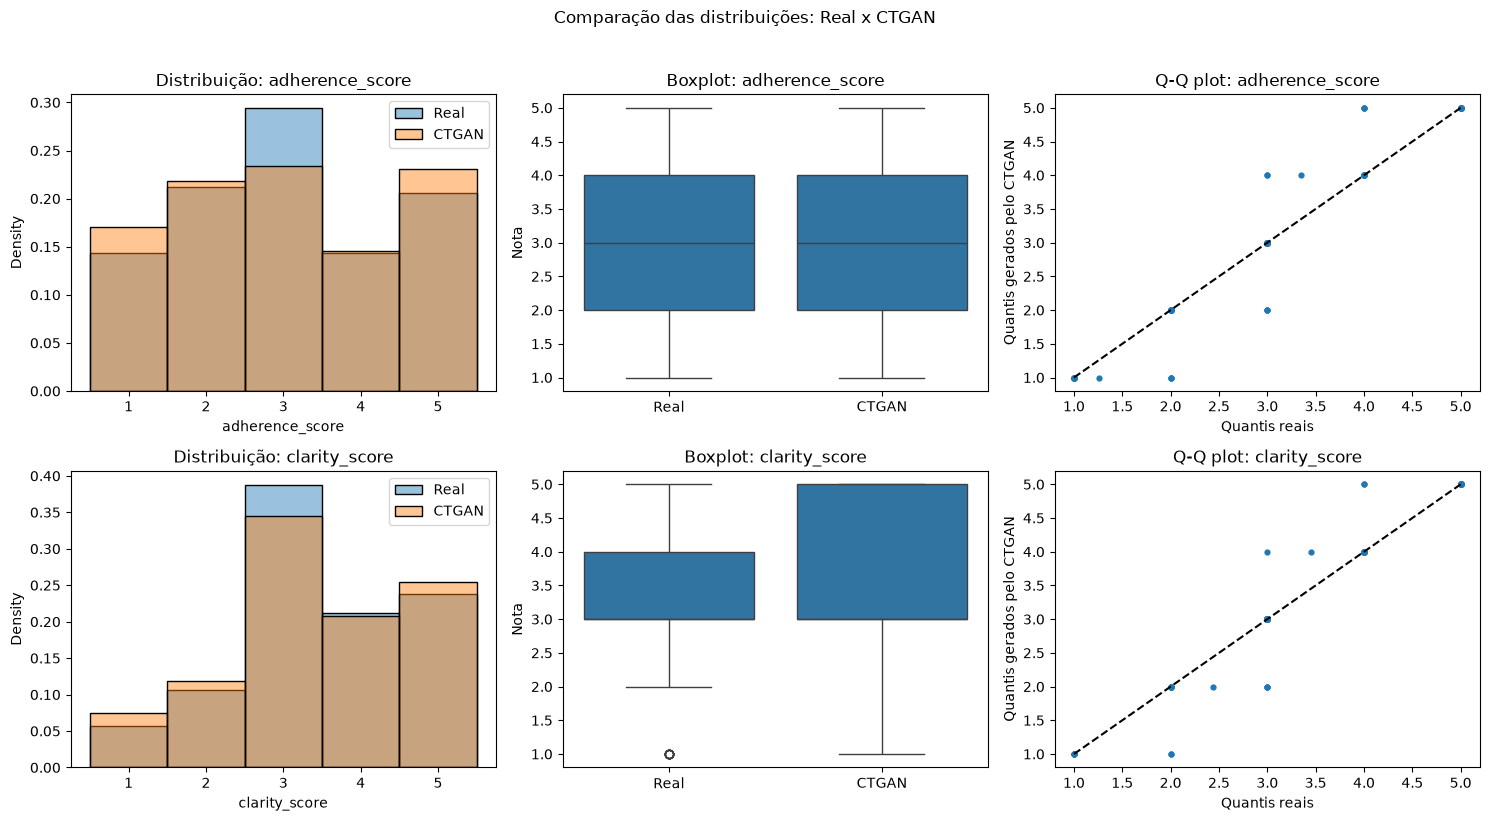

=== Avaliação do TVAE ===


,real_count,real_mean,real_std,real_min,real_25%,real_50%,real_75%,real_max,tvae_count,tvae_mean,tvae_std,tvae_min,tvae_25%,tvae_50%,tvae_75%,tvae_max
adherence_score,160.0,3.056,1.328,1.0,2.0,3.0,4.0,5.0,4090.0,2.973,1.239,1.0,2.0,3.0,4.0,5.0
clarity_score,160.0,3.469,1.132,1.0,3.0,3.0,4.0,5.0,4090.0,3.609,0.913,1.0,3.0,3.0,4.0,5.0


,erro
adherence_score,0.0289
clarity_score,0.0562
applied,0.0827


,distancia
applied,0.0827
adherence_score,0.1210
clarity_score,0.1847


Erro médio absoluto entre correlações: 0.0904


,valor
alpha_precisao,1.0000
beta_recall,0.9562
autenticidade,0.0000
raio_alpha,0.0000
raio_beta,0.0000


,acuracia,precisao,recall,f1
TRTR (real → real),0.7500,0.5882,0.6667,0.6250
TSTR (sintético → real),0.7708,0.6250,0.6667,0.6452
Real → sintético (diagnóstico),0.8954,0.7075,0.9287,0.8031


Registros novos gerados: 4090


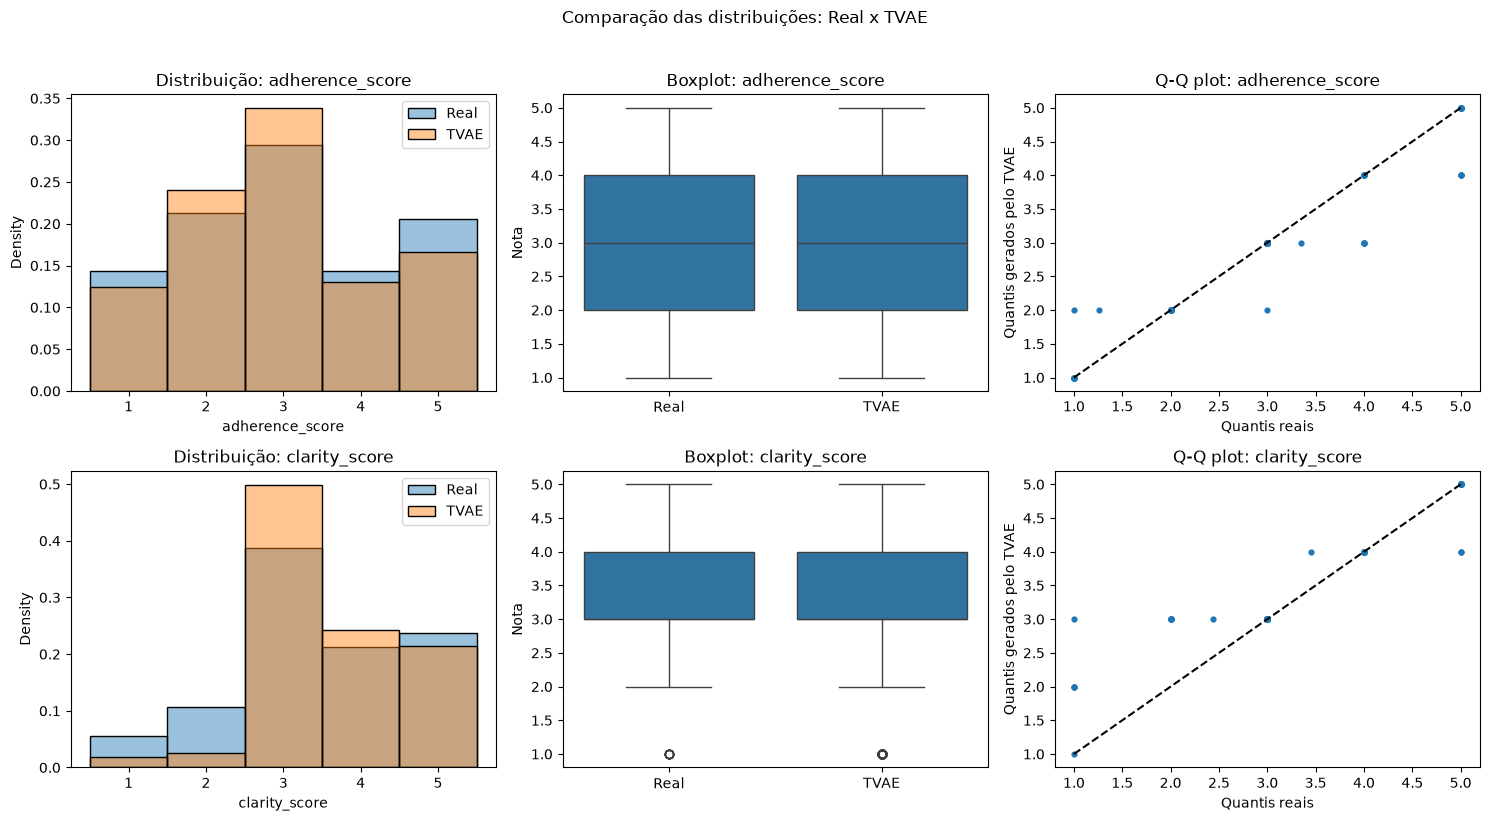

In [12]:
# Avaliação comum do CTGAN e do TVAE.
def avaliar_modelo_sdv(nome_modelo, sintetico, df_novas):
    colunas = ['applied', 'adherence_score', 'clarity_score']
    notas = ['adherence_score', 'clarity_score']
    real_modelo = df_treino[colunas].copy().astype(int)
    sintetico_modelo = sintetico[colunas].copy()
    if sintetico_modelo.empty:
        raise ValueError(f'Não há registros sintéticos novos para {nome_modelo}.')
    for coluna in colunas:
        sintetico_modelo[coluna] = pd.to_numeric(
            sintetico_modelo[coluna], errors='raise'
        ).astype(int)

    estados = {
        'adherence_score': [1, 2, 3, 4, 5],
        'clarity_score': [1, 2, 3, 4, 5],
        'applied': [0, 1],
    }
    erro_marginal_modelo = {}
    for coluna, estados_coluna in estados.items():
        tabela = pd.concat(
            [
                real_modelo[coluna].value_counts(normalize=True).reindex(
                    estados_coluna, fill_value=0
                ),
                sintetico_modelo[coluna].value_counts(
                    normalize=True
                ).reindex(estados_coluna, fill_value=0),
            ],
            axis=1, keys=['real', nome_modelo]
        )
        erro_marginal_modelo[coluna] = (
            tabela['real'] - tabela[nome_modelo]
        ).abs().mean()

    wasserstein_modelo = {
        coluna: wasserstein_distance(
            real_modelo[coluna], sintetico_modelo[coluna]
        )
        for coluna in colunas
    }
    corr_real_modelo = real_modelo[colunas].corr()
    corr_sintetico_modelo = sintetico_modelo[colunas].corr()
    mascara_modelo = np.triu(
        np.ones_like(corr_real_modelo, dtype=bool), k=1
    )
    erro_correlacao_modelo = np.abs(
        (corr_real_modelo - corr_sintetico_modelo).to_numpy()
    )[mascara_modelo].mean()

    escala_modelo = StandardScaler()
    Xr_modelo = escala_modelo.fit_transform(real_modelo[notas])
    Xs_modelo = escala_modelo.transform(sintetico_modelo[notas])
    metricas_vizinhanca_modelo = metricas_proximidade(
        Xr_modelo, Xs_modelo
    )

    real_train_modelo, real_test_modelo = train_test_split(
        real_modelo, test_size=.30, stratify=real_modelo['applied'],
        random_state=42
    )
    resultados_utility_modelo = pd.DataFrame({
        'TRTR (real → real)': medir(real_train_modelo, real_test_modelo),
        'TSTR (sintético → real)': medir(
            sintetico_modelo, real_test_modelo
        ),
        'Real → sintético (diagnóstico)': medir(
            real_train_modelo, sintetico_modelo
        ),
    }).T

    estatisticas_modelo = pd.concat(
        [
            real_modelo[notas].describe().T.add_prefix('real_'),
            sintetico_modelo[notas].describe().T.add_prefix(
                f'{nome_modelo.lower()}_'
            ),
        ], axis=1
    )
    print(f'=== Avaliação do {nome_modelo} ===')
    display(estatisticas_modelo.round(3))
    display(pd.Series(erro_marginal_modelo).to_frame('erro').round(4))
    display(pd.Series(wasserstein_modelo).to_frame('distancia').round(4))
    print(f'Erro médio absoluto entre correlações: {erro_correlacao_modelo:.4f}')
    display(pd.Series(metricas_vizinhanca_modelo).to_frame('valor').round(4))
    display(resultados_utility_modelo.round(4))
    print(f'Registros novos gerados: {len(df_novas)}')

    # Comparação gráfica das notas reais e geradas pelo modelo SDV.
    fig, axes = plt.subplots(
        len(notas),
        3,
        figsize=(15, 4 * len(notas))
    )
    axes = np.atleast_2d(axes)

    for i, coluna in enumerate(notas):
        sns.histplot(
            real_modelo[coluna],
            stat='density',
            discrete=True,
            alpha=.45,
            label='Real',
            ax=axes[i, 0]
        )
        sns.histplot(
            sintetico_modelo[coluna],
            stat='density',
            discrete=True,
            alpha=.45,
            label=nome_modelo,
            ax=axes[i, 0]
        )
        axes[i, 0].set_title(f'Distribuição: {coluna}')
        axes[i, 0].legend()

        dados_boxplot = pd.DataFrame({
            'nota': pd.concat(
                [
                    real_modelo[coluna].reset_index(drop=True),
                    sintetico_modelo[coluna].reset_index(drop=True)
                ],
                ignore_index=True
            ),
            'origem': (
                ['Real'] * len(real_modelo)
                + [nome_modelo] * len(sintetico_modelo)
            )
        })
        sns.boxplot(
            data=dados_boxplot,
            x='origem',
            y='nota',
            order=['Real', nome_modelo],
            ax=axes[i, 1]
        )
        axes[i, 1].set_title(f'Boxplot: {coluna}')
        axes[i, 1].set_xlabel('')
        axes[i, 1].set_ylabel('Nota')

        quantis = np.linspace(.01, .99, 99)
        quantis_reais = real_modelo[coluna].quantile(quantis)
        quantis_sinteticos = sintetico_modelo[coluna].quantile(quantis)
        axes[i, 2].scatter(
            quantis_reais,
            quantis_sinteticos,
            s=12
        )
        limites = [
            min(real_modelo[coluna].min(), sintetico_modelo[coluna].min()),
            max(real_modelo[coluna].max(), sintetico_modelo[coluna].max())
        ]
        axes[i, 2].plot(limites, limites, '--', color='black')
        axes[i, 2].set_title(f'Q-Q plot: {coluna}')
        axes[i, 2].set_xlabel('Quantis reais')
        axes[i, 2].set_ylabel(f'Quantis gerados pelo {nome_modelo}')

    fig.suptitle(f'Comparação das distribuições: Real x {nome_modelo}', y=1.02)
    plt.tight_layout()
    plt.show()

    return {
        'erro_marginal': erro_marginal_modelo,
        'wasserstein': wasserstein_modelo,
        'erro_correlacao': erro_correlacao_modelo,
        'Xr': Xr_modelo,
        'Xs': Xs_modelo,
        'metricas_vizinhanca': metricas_vizinhanca_modelo,
        'resultados_utility': resultados_utility_modelo,
    }

metricas_ctgan = avaliar_modelo_sdv(
    'CTGAN', sintetico_ctgan, df_novas_ctgan
)
metricas_tvae = avaliar_modelo_sdv(
    'TVAE', sintetico_tvae, df_novas_tvae
)

comparacao_ctgan = (
    comparar_metricas_com_ultimo_relatorio('metricas_ctgan.json', db_ors)
    if Path('metricas_ctgan.json').exists() else None
)
comparacao_tvae = (
    comparar_metricas_com_ultimo_relatorio('metricas_tvae.json', db_ors)
    if Path('metricas_tvae.json').exists() else None
)
for nome, comparacao in {
    'CTGAN': comparacao_ctgan, 'TVAE': comparacao_tvae
}.items():
    if comparacao is None:
        print(
            f'Copie metricas_{nome.lower()}.json para comparar '
            'as métricas de recomendação.'
        )

## Análise final: Qual dos modelos devemos escolher, com base nas métricas?

In [13]:
# Comparação histórica entre Copula e Rede Bayesiana.
# Critério: menor é melhor para erros/distâncias; maior é melhor para
# qualidade, cobertura, autenticidade e utilidade preditiva.
import json
from pathlib import Path

linhas_comparacao_final = []

def adicionar_comparacao(categoria, metrica, copula, bn, criterio):
    linhas_comparacao_final.append({
        'categoria': categoria,
        'metrica': metrica,
        'Copula': float(copula),
        'Rede Bayesiana': float(bn),
        'criterio': criterio,
    })

for coluna in erro_marginal:
    adicionar_comparacao(
        'Fidelidade', f'erro_marginal[{coluna}]',
        erro_marginal[coluna], erro_marginal_bn[coluna], 'menor'
    )

for coluna in wasserstein:
    adicionar_comparacao(
        'Fidelidade', f'wasserstein[{coluna}]',
        wasserstein[coluna], wasserstein_bn[coluna], 'menor'
    )

adicionar_comparacao(
    'Fidelidade', 'erro_correlacao',
    erro_correlacao, erro_correlacao_bn, 'menor'
)

proximidade_copula = metricas_proximidade(Xr, Xs)
proximidade_bn = metricas_vizinhanca_bn(Xr_bn, Xs_bn)
for metrica in ('alpha_precisao', 'beta_recall', 'autenticidade'):
    adicionar_comparacao(
        'Fidelidade', metrica,
        proximidade_copula[metrica], proximidade_bn[metrica], 'maior'
    )

for metrica in ('raio_alpha', 'raio_beta'):
    adicionar_comparacao(
        'Diagnóstico', metrica,
        proximidade_copula[metrica], proximidade_bn[metrica], 'informativo'
    )

metricas_utility = ('acuracia', 'precisao', 'recall', 'f1')
for metrica in metricas_utility:
    adicionar_comparacao(
        'Utilidade: sintético → real', metrica,
        resultados.loc['TSTR (sintético → real)', metrica],
        resultados_utility_bn.loc['BN-train (BN → real)', metrica],
        'maior'
    )
    adicionar_comparacao(
        'Utilidade: real → sintético', metrica,
        resultados.loc['Real → sintético (diagnóstico)', metrica],
        resultados_utility_bn.loc['Real-train (real → BN)', metrica],
        'maior'
    )

def carregar_metricas_recomendacao(caminho):
    documento = json.loads(Path(caminho).read_text(encoding='utf-8'))
    return {
        item['recommendation_engine']: item['metrics']
        for item in documento['results']
    }

metricas_copula = carregar_metricas_recomendacao(
    'metricas_copula.json'
)
metricas_bn = carregar_metricas_recomendacao(
    'metricas_bn.json'
)
campos_recomendacao = (
    'mean_precision_at_k', 'map_at_k', 'hit_ratio_at_k',
    'mrr_at_k', 'avg_first_relevant_pos', 'mean_ndcg_at_k',
    'mean_ep_at_k'
)
def obter_linha_comparacao(df_comparacao, engine, metrica):
    linhas = df_comparacao[
        (df_comparacao['recommendation_engine'] == engine)
        & (df_comparacao['metrica'] == metrica)
    ]
    if len(linhas) != 1:
        raise ValueError(
            f'Esperada uma comparação para {engine}/{metrica}; '
            f'encontradas {len(linhas)}.'
        )
    return linhas.iloc[0]

for engine in sorted(metricas_copula):
    for metrica in campos_recomendacao:
        comparacao_copula_metrica = obter_linha_comparacao(
            comparacao_copula, engine, metrica
        )
        comparacao_bn_metrica = obter_linha_comparacao(
            comparacao_bn, engine, metrica
        )

        valor_real = float(comparacao_copula_metrica['valor_mongo'])
        if not np.isclose(
            valor_real,
            float(comparacao_bn_metrica['valor_mongo']),
            rtol=1e-6,
            atol=1e-9
        ):
            raise ValueError(
                f'Valor real divergente para {engine}/{metrica}.'
            )

        adicionar_comparacao(
            f'Recomendação: {engine}', metrica,
            metricas_copula[engine][metrica],
            metricas_bn[engine][metrica],
            'menor_diferenca_absoluta'
        )
        linhas_comparacao_final[-1].update({
            'valor_real': valor_real,
            'diferenca_Copula': float(
                comparacao_copula_metrica['diferenca']
            ),
            'diferenca_BN': float(
                comparacao_bn_metrica['diferenca']
            ),
            'diferenca_absoluta_Copula': float(
                comparacao_copula_metrica['diferenca_absoluta']
            ),
            'diferenca_absoluta_BN': float(
                comparacao_bn_metrica['diferenca_absoluta']
            )
        })

comparacao_valores = pd.DataFrame(linhas_comparacao_final)
eh_recomendacao = comparacao_valores['categoria'].str.startswith(
    'Recomendação:'
)
comparacao_valores_gerais = comparacao_valores.loc[
    ~eh_recomendacao,
    ['categoria', 'metrica', 'Copula', 'Rede Bayesiana', 'criterio']
].reset_index(drop=True)
comparacao_valores_recomendacao = comparacao_valores.loc[
    eh_recomendacao,
    [
        'categoria', 'metrica', 'Copula', 'Rede Bayesiana',
        'valor_real', 'diferenca_Copula', 'diferenca_BN',
        'diferenca_absoluta_Copula', 'diferenca_absoluta_BN',
        'criterio'
    ]
].reset_index(drop=True)

print('=== Valores lado a lado: Fidelidade, Diagnóstico e Utilidade ===')
display(comparacao_valores_gerais.round(6))
print('=== Valores lado a lado: Recomendação ===')
display(comparacao_valores_recomendacao.round(6))

def obter_veredito(linha):
    if linha['criterio'] == 'informativo':
        return 'Informativo'
    if linha['criterio'] == 'menor_diferenca_absoluta':
        if np.isclose(
            abs(linha['diferenca_Copula']),
            abs(linha['diferenca_BN']),
            rtol=1e-6,
            atol=1e-9
        ):
            return 'Empate'
        return (
            'Copula'
            if abs(linha['diferenca_Copula'])
            < abs(linha['diferenca_BN'])
            else 'Rede Bayesiana'
        )
    if np.isclose(linha['Copula'], linha['Rede Bayesiana'], rtol=1e-6, atol=1e-9):
        return 'Empate'
    if linha['criterio'] == 'menor':
        return 'Copula' if linha['Copula'] < linha['Rede Bayesiana'] else 'Rede Bayesiana'
    return 'Copula' if linha['Copula'] > linha['Rede Bayesiana'] else 'Rede Bayesiana'

comparacao_vereditos = comparacao_valores.copy()
comparacao_vereditos['diferenca_Copula_menos_BN'] = (
    comparacao_vereditos['Copula'] - comparacao_vereditos['Rede Bayesiana']
)
comparacao_vereditos['veredito'] = comparacao_vereditos.apply(
    obter_veredito, axis=1
)
comparacao_vereditos_gerais = comparacao_vereditos.loc[
    ~eh_recomendacao,
    ['categoria', 'metrica', 'Copula', 'Rede Bayesiana',
     'criterio', 'veredito']
].reset_index(drop=True)
comparacao_vereditos_recomendacao = comparacao_vereditos.loc[
    eh_recomendacao,
    [
        'categoria', 'metrica', 'Copula', 'Rede Bayesiana',
        'valor_real', 'diferenca_Copula', 'diferenca_BN',
        'diferenca_absoluta_Copula', 'diferenca_absoluta_BN',
        'criterio', 'veredito'
    ]
].reset_index(drop=True)

print('=== Vereditos: Fidelidade, Diagnóstico e Utilidade ===')
display(comparacao_vereditos_gerais.round(6))
print('=== Vereditos: Recomendação ===')
display(comparacao_vereditos_recomendacao.round(6))

pontuacao = (
    comparacao_vereditos[comparacao_vereditos['veredito'].isin(
        ['Copula', 'Rede Bayesiana']
    )]
    .groupby(['categoria', 'veredito'])
    .size()
    .unstack(fill_value=0)
)
print('=== Pontuação por categoria ===')
display(pontuacao)

vitorias = comparacao_vereditos['veredito'].value_counts()
copula_vitorias = int(vitorias.get('Copula', 0))
bn_vitorias = int(vitorias.get('Rede Bayesiana', 0))
if copula_vitorias == bn_vitorias:
    vencedor_geral = 'Empate'
else:
    vencedor_geral = 'Copula' if copula_vitorias > bn_vitorias else 'Rede Bayesiana'
print(
    f'Vencedor geral: {vencedor_geral} '
    f'({copula_vitorias} vitórias Copula x {bn_vitorias} vitórias BN)'
)

=== Valores lado a lado: Fidelidade, Diagnóstico e Utilidade ===


,categoria,metrica,Copula,Rede Bayesiana,criterio
0,Fidelidade,erro_marginal[applied],0.015434,0.005899,menor
1,Fidelidade,erro_marginal[adherence_score],0.004053,0.005238,menor
2,Fidelidade,erro_marginal[clarity_score],0.014377,0.008362,menor
3,Fidelidade,wasserstein[applied],0.015434,0.005899,menor
4,Fidelidade,wasserstein[adherence_score],0.013921,0.021990,menor
5,Fidelidade,wasserstein[clarity_score],0.063432,0.060193,menor
6,Fidelidade,erro_correlacao,0.390937,0.309458,menor
7,Fidelidade,alpha_precisao,0.926650,0.919804,maior
8,Fidelidade,beta_recall,1.000000,1.000000,maior
9,Fidelidade,autenticidade,0.073350,0.080196,maior


=== Valores lado a lado: Recomendação ===


,categoria,metrica,Copula,Rede Bayesiana,valor_real,diferenca_Copula,diferenca_BN,diferenca_absoluta_Copula,diferenca_absoluta_BN,criterio
0,Recomendação: bm25,mean_precision_at_k,0.284977,0.377934,0.306667,-0.021690,0.071268,0.021690,0.071268,menor_diferenca_absoluta
1,Recomendação: bm25,map_at_k,0.446068,0.557205,0.367500,0.078568,0.189705,0.078568,0.189705,menor_diferenca_absoluta
2,Recomendação: bm25,hit_ratio_at_k,0.819249,0.894366,0.600000,0.219249,0.294366,0.219249,0.294366,menor_diferenca_absoluta
3,Recomendação: bm25,mrr_at_k,0.463146,0.595970,0.380000,0.083146,0.215970,0.083146,0.215970,menor_diferenca_absoluta
4,Recomendação: bm25,avg_first_relevant_pos,2.159149,1.677936,2.631579,-0.472430,-0.953643,0.472430,0.953643,menor_diferenca_absoluta
5,Recomendação: bm25,mean_ndcg_at_k,0.897753,0.891497,0.895679,0.002074,-0.004182,0.002074,0.004182,menor_diferenca_absoluta
6,Recomendação: bm25,mean_ep_at_k,0.449296,0.438028,0.466667,-0.017371,-0.028638,0.017371,0.028638,menor_diferenca_absoluta
7,Recomendação: jaccard,mean_precision_at_k,0.301887,0.303774,0.280000,0.021887,0.023774,0.021887,0.023774,menor_diferenca_absoluta
8,Recomendação: jaccard,map_at_k,0.456112,0.456607,0.465926,-0.009814,-0.009319,0.009814,0.009319,menor_diferenca_absoluta
9,Recomendação: jaccard,hit_ratio_at_k,0.825472,0.825472,0.733333,0.092138,0.092138,0.092138,0.092138,menor_diferenca_absoluta


=== Vereditos: Fidelidade, Diagnóstico e Utilidade ===


,categoria,metrica,Copula,Rede Bayesiana,criterio,veredito
0,Fidelidade,erro_marginal[applied],0.015434,0.005899,menor,Rede Bayesiana
1,Fidelidade,erro_marginal[adherence_score],0.004053,0.005238,menor,Copula
2,Fidelidade,erro_marginal[clarity_score],0.014377,0.008362,menor,Rede Bayesiana
3,Fidelidade,wasserstein[applied],0.015434,0.005899,menor,Rede Bayesiana
4,Fidelidade,wasserstein[adherence_score],0.013921,0.021990,menor,Copula
5,Fidelidade,wasserstein[clarity_score],0.063432,0.060193,menor,Rede Bayesiana
6,Fidelidade,erro_correlacao,0.390937,0.309458,menor,Rede Bayesiana
7,Fidelidade,alpha_precisao,0.926650,0.919804,maior,Copula
8,Fidelidade,beta_recall,1.000000,1.000000,maior,Empate
9,Fidelidade,autenticidade,0.073350,0.080196,maior,Rede Bayesiana


=== Vereditos: Recomendação ===


,categoria,metrica,Copula,Rede Bayesiana,valor_real,diferenca_Copula,diferenca_BN,diferenca_absoluta_Copula,diferenca_absoluta_BN,criterio,veredito
0,Recomendação: bm25,mean_precision_at_k,0.284977,0.377934,0.306667,-0.021690,0.071268,0.021690,0.071268,menor_diferenca_absoluta,Copula
1,Recomendação: bm25,map_at_k,0.446068,0.557205,0.367500,0.078568,0.189705,0.078568,0.189705,menor_diferenca_absoluta,Copula
2,Recomendação: bm25,hit_ratio_at_k,0.819249,0.894366,0.600000,0.219249,0.294366,0.219249,0.294366,menor_diferenca_absoluta,Copula
3,Recomendação: bm25,mrr_at_k,0.463146,0.595970,0.380000,0.083146,0.215970,0.083146,0.215970,menor_diferenca_absoluta,Copula
4,Recomendação: bm25,avg_first_relevant_pos,2.159149,1.677936,2.631579,-0.472430,-0.953643,0.472430,0.953643,menor_diferenca_absoluta,Copula
5,Recomendação: bm25,mean_ndcg_at_k,0.897753,0.891497,0.895679,0.002074,-0.004182,0.002074,0.004182,menor_diferenca_absoluta,Copula
6,Recomendação: bm25,mean_ep_at_k,0.449296,0.438028,0.466667,-0.017371,-0.028638,0.017371,0.028638,menor_diferenca_absoluta,Copula
7,Recomendação: jaccard,mean_precision_at_k,0.301887,0.303774,0.280000,0.021887,0.023774,0.021887,0.023774,menor_diferenca_absoluta,Copula
8,Recomendação: jaccard,map_at_k,0.456112,0.456607,0.465926,-0.009814,-0.009319,0.009814,0.009319,menor_diferenca_absoluta,Rede Bayesiana
9,Recomendação: jaccard,hit_ratio_at_k,0.825472,0.825472,0.733333,0.092138,0.092138,0.092138,0.092138,menor_diferenca_absoluta,Empate


=== Pontuação por categoria ===


veredito,Copula,Rede Bayesiana
categoria,,
Fidelidade,3,6
Recomendação: bm25,7,0
Recomendação: jaccard,4,2
Utilidade: real → sintético,0,4
Utilidade: sintético → real,0,3


Vencedor geral: Rede Bayesiana (14 vitórias Copula x 15 vitórias BN)


In [14]:
# Comparação final ampliada incluindo CTGAN e TVAE.
modelos_sinteticos = {
    'Copula': {
        'erro_marginal': erro_marginal,
        'wasserstein': wasserstein,
        'erro_correlacao': erro_correlacao,
        'proximidade': metricas_proximidade(Xr, Xs),
        'utility': resultados,
        'recomendacao': comparacao_copula,
    },
    'Rede Bayesiana': {
        'erro_marginal': erro_marginal_bn,
        'wasserstein': wasserstein_bn,
        'erro_correlacao': erro_correlacao_bn,
        'proximidade': metricas_vizinhanca_bn(Xr_bn, Xs_bn),
        'utility': {
            'TSTR (sintético → real)': resultados_utility_bn.loc['BN-train (BN → real)'],
            'Real → sintético (diagnóstico)': resultados_utility_bn.loc['Real-train (real → BN)'],
        },
        'recomendacao': comparacao_bn,
    },
    'CTGAN': {**metricas_ctgan, 'recomendacao': comparacao_ctgan},
    'TVAE': {**metricas_tvae, 'recomendacao': comparacao_tvae},
}

# Padroniza os nomes das métricas de proximidade e utility dos modelos SDV.
for nome in ('CTGAN', 'TVAE'):
    modelos_sinteticos[nome]['proximidade'] = modelos_sinteticos[nome].pop('metricas_vizinhanca')
    modelos_sinteticos[nome]['utility'] = modelos_sinteticos[nome].pop('resultados_utility')

nomes_modelos = list(modelos_sinteticos)
linhas_comparacao_expandida = []

def adicionar_linha_expandida(categoria, metrica, valores, criterio):
    valores = {nome: float(valor) for nome, valor in valores.items()}
    if criterio == 'menor':
        melhor = min(valores.values())
    elif criterio == 'maior':
        melhor = max(valores.values())
    else:
        melhor = None
    vencedores = [] if melhor is None else [
        nome for nome, valor in valores.items()
        if np.isclose(valor, melhor, rtol=1e-6, atol=1e-9)
    ]
    linhas_comparacao_expandida.append({
        'categoria': categoria, 'metrica': metrica, **valores,
        'criterio': criterio,
        'veredito': 'Informativo' if melhor is None else (
            vencedores[0] if len(vencedores) == 1 else 'Empate'
        ),
    })

for metrica in modelos_sinteticos['Copula']['erro_marginal']:
    adicionar_linha_expandida(
        'Fidelidade', f'erro_marginal[{metrica}]',
        {nome: dados['erro_marginal'][metrica] for nome, dados in modelos_sinteticos.items()}, 'menor'
    )
    adicionar_linha_expandida(
        'Fidelidade', f'wasserstein[{metrica}]',
        {nome: dados['wasserstein'][metrica] for nome, dados in modelos_sinteticos.items()}, 'menor'
    )
adicionar_linha_expandida(
    'Fidelidade', 'erro_correlacao',
    {nome: dados['erro_correlacao'] for nome, dados in modelos_sinteticos.items()}, 'menor'
)
for metrica in ('alpha_precisao', 'beta_recall', 'autenticidade'):
    adicionar_linha_expandida(
        'Fidelidade', metrica,
        {nome: dados['proximidade'][metrica] for nome, dados in modelos_sinteticos.items()}, 'maior'
    )
for metrica in ('raio_alpha', 'raio_beta'):
    adicionar_linha_expandida(
        'Diagnóstico', metrica,
        {nome: dados['proximidade'][metrica] for nome, dados in modelos_sinteticos.items()}, 'informativo'
    )
def obter_valor_utility(dados, linha, metrica):
    utility = dados['utility']
    if hasattr(utility, 'loc'):
        return utility.loc[linha, metrica]
    return utility[linha][metrica]

for metrica in ('acuracia', 'precisao', 'recall', 'f1'):
    for categoria, linha in (
        ('Utilidade: sintético → real', 'TSTR (sintético → real)'),
        ('Utilidade: real → sintético', 'Real → sintético (diagnóstico)'),
    ):
        adicionar_linha_expandida(
            categoria, metrica,
            {nome: obter_valor_utility(dados, linha, metrica) for nome, dados in modelos_sinteticos.items()}, 'maior'
        )

# As métricas de recomendação entram quando os JSONs de CTGAN/TVAE existem.
comparacoes_recomendacao = {
    nome: dados['recomendacao'] for nome, dados in modelos_sinteticos.items()
    if dados['recomendacao'] is not None
}
if len(comparacoes_recomendacao) >= 2:
    for engine in sorted(metricas_copula):
        for metrica in campos_recomendacao:
            erros = {}
            for nome, tabela in comparacoes_recomendacao.items():
                linha = tabela[
                    (tabela['recommendation_engine'] == engine)
                    & (tabela['metrica'] == metrica)
                ]
                if len(linha) != 1:
                    raise ValueError(f'Comparação ausente para {nome}/{engine}/{metrica}.')
                erros[nome] = float(linha.iloc[0]['diferenca_absoluta'])
            adicionar_linha_expandida(
                f'Recomendação: {engine}', f'{metrica} (erro absoluto)',
                erros, 'menor'
            )
else:
    print('Métricas de recomendação CTGAN/TVAE ainda não incluídas: JSON ausente.')

comparacao_expandida = pd.DataFrame(linhas_comparacao_expandida)
print('=== Comparação final ampliada ===')
display(comparacao_expandida.round(6))
pontuacao_expandida = (
    comparacao_expandida[comparacao_expandida['veredito'].isin(nomes_modelos)]
    .groupby(['categoria', 'veredito']).size().unstack(fill_value=0)
)
print('=== Pontuação por categoria ===')
display(pontuacao_expandida)
vitorias_expandida = comparacao_expandida['veredito'].value_counts()
print('=== Vitórias por modelo ===')
display(vitorias_expandida.reindex(nomes_modelos, fill_value=0).to_frame('vitorias'))
maior_pontuacao = vitorias_expandida.reindex(nomes_modelos, fill_value=0).max()
vencedores_gerais = vitorias_expandida.reindex(nomes_modelos, fill_value=0)
vencedores_gerais = vencedores_gerais[vencedores_gerais == maior_pontuacao].index.tolist()
print(f'Veredito geral: {"Empate" if len(vencedores_gerais) > 1 else vencedores_gerais[0]}')

=== Comparação final ampliada ===


,categoria,metrica,Copula,Rede Bayesiana,CTGAN,TVAE,criterio,veredito
0,Fidelidade,erro_marginal[applied],0.015434,0.005899,0.045446,0.082671,menor,Rede Bayesiana
1,Fidelidade,wasserstein[applied],0.015434,0.005899,0.045446,0.082671,menor,Rede Bayesiana
2,Fidelidade,erro_marginal[adherence_score],0.004053,0.005238,0.023808,0.028894,menor,Copula
3,Fidelidade,wasserstein[adherence_score],0.013921,0.021990,0.111721,0.121012,menor,Copula
4,Fidelidade,erro_marginal[clarity_score],0.014377,0.008362,0.019169,0.056235,menor,Rede Bayesiana
5,Fidelidade,wasserstein[clarity_score],0.063432,0.060193,0.078102,0.184734,menor,Rede Bayesiana
6,Fidelidade,erro_correlacao,0.390937,0.309458,0.455067,0.090430,menor,TVAE
7,Fidelidade,alpha_precisao,0.926650,0.919804,0.923227,1.000000,maior,TVAE
8,Fidelidade,beta_recall,1.000000,1.000000,1.000000,0.956250,maior,Empate
9,Fidelidade,autenticidade,0.073350,0.080196,0.076773,0.000000,maior,Rede Bayesiana


=== Pontuação por categoria ===


veredito,CTGAN,Copula,Rede Bayesiana,TVAE
categoria,,,,
Fidelidade,0,2,5,2
Recomendação: bm25,2,1,0,4
Recomendação: jaccard,2,3,1,1
Utilidade: real → sintético,0,0,0,4
Utilidade: sintético → real,0,0,1,2


=== Vitórias por modelo ===


,vitorias
veredito,
Copula,6
Rede Bayesiana,7
CTGAN,4
TVAE,13


Veredito geral: TVAE


## Conclusão

A comparação final ampliada considera Copula, Rede Bayesiana, CTGAN e TVAE nas métricas de fidelidade, proximidade, utilidade e recomendação. O veredito geral é calculado pela contagem de vitórias por métricas, as diferenças obtidas e análises mais específicas. 

Pelo total de vitórias, TVAE foi o vencedor, porém ele teve uma alta precisão e 0% de autenticidade, indicando que estava só copiando e colando os dados de treino. A **Rede Bayesiana** ficou em segundo, porém ficou mais equilibrada do ponto de vista geral, além de ser mais interpretável e baixo custo computacional e de tempo, o que poderia justificar sua escolha.